# Where a coding model decides its algorithm: Stage A full-state exchange (demo)

**Artifact `art_rMlbrjVB1c__` (experiment).** bf16 **Qwen3-8B** (rev `b968826d`) almost always writes one *default* algorithm per coding task: Dijkstra for weighted shortest paths (T2), a full sort for the k-th smallest element (T03), union-find for connected components (T10), BFS on a grid (T1), a hash map for two-sum (T05), a hash set for find-duplicate (T06). A prompt that **bans** the default (*"Do not use Dijkstra's algorithm for this task."*) moves the model to a substitute **Y** (Bellman-Ford/SPFA on T2, quickselect on T03, BFS on T10, ...). The artifact asks **where in the prompt's internal states that choice is carried**.

**Method (Stage A).** Every ban has a *neutral twin* of identical token length (*"Do not use man and the house for this task."*). The two prompts differ only in a short **condition span** before `Task:` and are token-identical from `Task:` on. The twin is run with its residual-stream block outputs at the **task-specification positions** overwritten by the ban's (*full-state exchange*, cells `X_b`, one per band `b` of decoder blocks). It is compared with `COND` (a KV splice of only the condition span, the *direct* route), `RPOS` (an exchange at the read position only) and two controls: `MR` (a matched-norm random exchange) and `PLACEBO` (a second neutral twin as the source). All arms of a slot share one stream of uniforms (**common random numbers**, CRN), so a program changes only if the intervention changes the model's next-token distribution.

**Full-run results (Qwen3-8B, N = 30 CRN slots per cell).** On *prompt-route* tasks the ban is carried by the task-spec states: on T2, exchanging the spec states of all 36 blocks moves 24 of 30 slots from Dijkstra to Bellman-Ford/SPFA (transfer 0.80, McNemar 24:0, Holm p 7e-7), while the condition-span splice moves none. On *direct-route* tasks the splice alone reproduces the ban (T05 1.00, T06 0.90). The read position transfers nothing, MR at most 0.13 and the placebo at most 0.03.

**What this notebook runs (a few minutes on a CPU):**
1. **Live mini-exchange.** The artifact's own Stage A code (`stage_twins_A` from `src/gpu6.py` on the exp27 CRN engine) on a small Qwen3 (`Qwen/Qwen3-0.6B`, 28 blocks), for one task, one template and a few CRN slots. It shows the mechanism end to end. A 0.6B model is **not** the 8B model, so its behaviour is illustrative only.
2. **Re-analysis of the recorded Qwen3-8B programs.** The original `stage_a` (`src/analysis6.py`) and `src/stats6.py` on all 1,830 labelled Stage A programs in `mini_demo_data.json`: transfer, exact McNemar with Holm, the committed verdicts, a check of every number against the artifact's own `results/stage_a.json`, the audit's swap placebo, and Figure F1.

The original pipeline (`method.py`) runs 12 stages as separate processes on one 16 GB GPU (about 2.7 GPU-hours); its stage table is shown below.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install
_pip('loguru==0.7.3')

# Core packages (pre-installed on Colab, install locally to match Colab env)
if 'google.colab' not in sys.modules:
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0',
         'transformers==5.0.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

In [2]:
from __future__ import annotations

# method.py
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# src/gpu6.py, src/engine_v4.py, src/engine5.py, src/engine6.py, src/cfg.py, src/cfg6.py
import argparse
import contextlib
import gc
import hashlib
import json
import math
import re
from collections import Counter, defaultdict
from datetime import datetime, timezone
from typing import Any, Callable, Iterable, Iterator

import numpy as np
import torch

# src/stats6.py
from scipy import optimize, stats

# audit/rederive.py (Python standard library only)
import random

# notebook additions: tables, plots, and a namespace standing in for `import stats6 as S`
from types import SimpleNamespace

import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-6/experiment-30/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(f"{data['dataset']}: {data['n_examples']} (task, cell) examples holding {data['n_programs']} labelled "
      f"{data['model']} programs, {len(data['prompts'])} prompts")
for ex in data["examples"][:3]:
    print(" ", ex["input"], "->", ex["output"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
stage_a_exchange: 57 (task, cell) examples holding 1830 labelled Qwen/Qwen3-8B programs, 90 prompts
  Stage A | task=T03 cell=TWIN: neutral twin (token-length-matched, no ban) -> full_sort:50
  Stage A | task=T03 cell=BAN: full ban of the default algorithm -> quickselect:20 size_k_heap:10
  Stage A | task=T03 cell=X_0-11: ban's residual states exchanged into the twin at the task-spec positions, blocks 0-11 -> full_sort:14 quickselect:12 size_k_heap:4


## Configuration

All tunable parameters are set here. The values are the demo scale (CPU, under 10 minutes in total); the comments give the original values of the full run (bf16 Qwen3-8B on one 16 GB GPU, about 2.7 GPU-hours for all stages).

To run Stage A at the original scale:
- set `MODEL_ID = "Qwen/Qwen3-8B"`, `MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"`;
- set the tasks, templates, slots, caps and batch sizes to their originals;
- use a CUDA GPU with at least 16 GB.

In [5]:
# ---------------------------------------------------------------- Part 1: live mini-exchange on a small Qwen3
MODEL_ID = "Qwen/Qwen3-0.6B"   # original "Qwen/Qwen3-8B" (36 blocks, d_model 4096, bf16 on a >= 16 GB GPU)
MODEL_REVISION = None          # original "b968826d9c46dd6066d109eabc6255188de91218"
LIVE_TASKS = ("T03",)          # original TASKS6 = ("T03", "T10", "T2", "T05", "T06", "T1")
LIVE_TEMPLATES = ("W1", "W2")  # original TEMPLATES6 = ("W1", "W2", "W3", "W5")
N_LIVE_SLOTS = 4               # CRN slots per template; original 30 per exchange cell (N30) and 50 for TWIN (N50)
MAX_NEW_LIVE = 256             # token cap per program; original MAX_NEW6 = 384 (bench) / 512 (T2) / 640 (T1)
BATCH_LIVE = 11                # fixed batch size B; original BATCH6 = 10 (bench) / 8 (T2) / 6 (T1)
TORCH_THREADS = 2              # CPU threads (a Colab CPU runtime has 2)
# ---------------------------------------------------------------- Part 2: analysis of the recorded Qwen3-8B programs
N_SLOTS_ANALYSIS = 30          # CRN slots 0..N-1 analysed per exchange cell; original 30
N_PERM = 2000                  # permutations of the audit's swap placebo; original 2000

## 1. The original pipeline (`method.py`)

`method.py` is the artifact's entry point. It runs every stage in its own process, because the GPU holds one model at a time, and each stage resumes from its own output files.

Below is the original code: the stage table, the order and `main()`. Two things differ:
- `ROOT` is the notebook's working directory;
- `main()` is **not** called, because the stages need the artifact's `src/` tree, its `.venv` and a 16 GB GPU.

The table printed underneath says where this notebook reproduces each stage.

In [6]:
# method.py -- the artifact's entry point, unchanged except ROOT (a notebook has no __file__) and the final call
ROOT = Path.cwd()  # notebook: original Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")

STAGES = {
    "prompts": [[PY, "src/prompts6.py"]],                                 # STEP 0-1 (CPU): prompts, positions, dep
    "utest": [[PY, "src/gpu6.py", "utest"]],                              # STEP 2 (GPU): U1-U5
    "commit0": [[PY, "src/prereg6.py"]],                                  # commit #0 before any decisive sample
    "gpu": [["bash", "scripts/run_gpu_main.sh", "175"]],                  # STEPS 4-8 (GPU, deadline in minutes)
    "ext": [[PY, "src/gpu6.py", "ext", "--deadline-min", "25"]],           # STEP 9 extensions (forced, seed, W4)
    "label": [[PY, "src/label6.py"]],                                     # STEP 10 (CPU worker; follows the GPU)
    "lgpu": [[PY, "src/lcontest.py", "events"], [PY, "src/lcontest.py", "open"]],  # STEP 3 (L teacher-forced)
    "analysis": [[PY, "src/analysis6.py"], [PY, "src/lcontest.py", "score"]],
    "novelty": [[PY, "src/novelty6.py"]],
    "figures": [[PY, "src/figures6.py"]],
    "outputs": [[PY, "src/bookkeeping6.py"], [PY, "src/outputs6.py"]],
    "audit": [["python3", "-I", "audit/rederive.py"]],
}
ORDER = ["prompts", "utest", "commit0", "gpu", "ext", "lgpu", "label", "analysis", "novelty", "figures", "outputs",
         "audit"]


@logger.catch(reraise=True)
def main() -> None:
    want = sys.argv[1:] or ["all"]
    stages = ORDER if want == ["all"] else want
    for st in stages:
        for cmd in STAGES[st]:
            t0 = time.time()
            logger.info(f"stage {st}: {' '.join(cmd)}")
            if st == "label" and "all" in want:
                (ROOT / "results" / "gpu_all_done.flag").write_text("done\n")  # the GPU work above has finished
            r = subprocess.run(cmd, cwd=ROOT)
            logger.info(f"stage {st} exit {r.returncode} in {time.time() - t0:.0f}s")
            if r.returncode != 0:
                raise RuntimeError(f"stage {st} failed ({' '.join(cmd)})")


# if __name__ == "__main__":
#     main()  # notebook: not called -- the stages need the artifact's src/ tree, its .venv and a 16 GB GPU

# notebook addition: where (if at all) this notebook reproduces each stage
NOTEBOOK_COVERAGE = {
    "prompts": "section 2.1: twin / ban / placebo prompts + positions, from mini_demo_data.json",
    "utest": "not run (U1-U5 byte-identity unit tests of the engine)",
    "commit0": "not run (sha256 commitment chain of every rule, commitments.log)",
    "gpu": "section 3: Stage A (stage_twins_A) live on a small Qwen3; ST / DMD / top-five push not run",
    "ext": "not run (forced 'Implement Y', semantic seed and W4 extensions)",
    "lgpu": "not run (L contest: teacher-forced opening rankings)",
    "label": "not run: needs the exp8 / exp11 runtime-tracer + AST labellers; Part 2 uses the recorded labels",
    "analysis": "section 4: analysis6.stage_a + stats6 on the recorded Qwen3-8B rows",
    "novelty": "not run (two-family OpenRouter novelty audit of correct 'other' programs)",
    "figures": "section 5: Figure F1 (Stage A transfer heat maps) + a summary figure",
    "outputs": "not run (method_out.json writer)",
    "audit": "sections 4.2-4.3: rederive-style check and the Stage A swap placebo",
}
print(pd.DataFrame({"command": {s: " ; ".join(" ".join(c) for c in STAGES[s]).replace(PY, ".venv/bin/python")
                                for s in ORDER},
                    "in this notebook": NOTEBOOK_COVERAGE}).to_string())

                                                                                  command                                                                                 in this notebook
prompts                                                  .venv/bin/python src/prompts6.py                  section 2.1: twin / ban / placebo prompts + positions, from mini_demo_data.json
utest                                                  .venv/bin/python src/gpu6.py utest                                           not run (U1-U5 byte-identity unit tests of the engine)
commit0                                                   .venv/bin/python src/prereg6.py                                 not run (sha256 commitment chain of every rule, commitments.log)
gpu                                                      bash scripts/run_gpu_main.sh 175       section 3: Stage A (stage_twins_A) live on a small Qwen3; ST / DMD / top-five push not run
ext                                    .venv/bin/python src/gpu6.

## 2. Shared constants and the Stage A prompts

The constants come from `src/cfg.py` (exp27's conventions) and `src/cfg6.py` (iteration 6):
- the six tasks, each with its default algorithm, its recorded substitute `Y`, and the route class found in iterations 2-3;
- the CRN slot map: slot `s` → template `w` and stream index `k`;
- the generation caps and the fixed batch sizes.

They are copied verbatim. Only the original output paths (`data/`, `results/`) are replaced by local demo files.

In [7]:
# ---------------------------------------------------------------- src/cfg.py (excerpt)
IM_END = 151645
ENDOFTEXT = 151643
MAX_NEW_TOKENS = 1024          # bench tasks and the engine check (the exp17 screen's cap)
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
RESULTS_DIR = ROOT / "demo_results"  # notebook: a local output folder (original: results/)
RESULTS_DIR.mkdir(exist_ok=True)


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
        fh.flush()


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def append_deviation(did: str, text: str) -> None:
    p = RESULTS_DIR / "deviations.jsonl"
    rows = read_jsonl(p)
    if any(r.get("id") == did for r in rows):
        return
    append_jsonl(p, [{"id": did, "utc": utc_now(), "deviation": text}])
    logger.warning(f"DEVIATION {did}: {text}")


# ---------------------------------------------------------------- src/cfg6.py (excerpt)
TASKS6 = ("T03", "T10", "T2", "T05", "T06", "T1")
BENCH6 = ("T03", "T10", "T05", "T06")
PATH6 = ("T1", "T2")
DEFAULT6 = {"T03": "full_sort", "T10": "union_find", "T2": "dijkstra", "T05": "hash_map", "T06": "hash_set",
            "T1": "bfs"}
# Y = the recorded substitute the full ban lands on (frozen in commit #0 from iterations 2-5); T2 Bellman-Ford/SPFA
# carries the exp8 suite label "bf_spfa"
Y6 = {"T2": "bf_spfa", "T03": "quickselect", "T10": "bfs", "T1": "dfs", "T05": "brute_force",
      "T06": "index_marking"}
# route classes of iterations 2-3 (bf16 route arms c/d): prompt route (the ban is read into the task-spec states)
# versus direct route (generated tokens read the condition span)
ROUTE_CLASS = {"T2": "prompt", "T03": "prompt", "T10": "prompt", "T1": "prompt", "T05": "direct", "T06": "direct"}
TEMPLATES6 = ("W1", "W2", "W3", "W5")

# ------------------------------------------------------------------------------------------------ slots
_SLOT_SPEC = [("W1", range(0, 8)), ("W2", range(0, 8)), ("W3", range(0, 7)), ("W5", range(0, 7)),     # 0-29
              ("W1", range(8, 10)), ("W2", range(8, 10)), ("W3", range(7, 10)), ("W5", range(7, 10)),  # 30-39
              ("W1", range(10, 13)), ("W2", range(10, 13)), ("W3", range(10, 12)), ("W5", range(10, 12))]  # 40-49
SLOT_MAP: list[tuple[str, int]] = [(w, k) for w, ks in _SLOT_SPEC for k in ks]
assert len(SLOT_MAP) == 50 and len(set(SLOT_MAP)) == 50
SLOT_MAP += [("W4", k) for k in range(10)]  # slots 50-59: the W4 template, reported separately (extension)
N_W4 = tuple(range(50, 60))
SLOT_OF = {wk: s for s, wk in enumerate(SLOT_MAP)}
N30 = tuple(range(30))
N50 = tuple(range(50))

# ------------------------------------------------------------------------------------------------ engine
MAX_NEW6 = {"T03": 384, "T10": 384, "T05": 384, "T06": 384, "T2": 512, "T1": 640}
BATCH6 = {"T03": 10, "T10": 10, "T05": 10, "T06": 10, "T2": 8, "T1": 6}   # fixed per task family (GEMM shapes)
PRECISION6 = "bf16"
ENGINE6 = "hf_bf16_cpu_embed"
SITE_BLOCKS6 = {"S0": list(range(12, 24)), "S4": list(range(0, 12)), "S5": list(range(24, 36)),
                "S1": list(range(12, 24)), "S2": list(range(12, 24)), "S3": list(range(12, 24)),
                "S1E": list(range(12, 24)), "S2E": list(range(12, 24)), "TOP5": list(range(12, 24))}
S3_STEPS6 = 32


def dir_seed(task: str, site: str, alpha: float | str, slot: int) -> int:
    s = "iter6_dir3|" + task + "|" + site + "|" + str(alpha) + "|" + str(slot)
    return int(hashlib.sha256(s.encode()).hexdigest()[:8], 16)


def sample_id(task: str, arm: str, slot: int) -> str:
    w, k = SLOT_MAP[slot]
    return f"{task}|{arm}|{w}|{k}"


def max_new6(task: str) -> int:
    return MAX_NEW6[task]


def fence6(task: str) -> str:
    return "path" if task in PATH6 else "bench"


SAMPLES = ROOT / "demo_out" / "samples_raw_demo.jsonl"  # notebook: the live run's rows (original: data/samples_raw.jsonl)

### 2.1 Twin, ban and placebo prompts (`src/prompts6.py`)

`prompts6.py` builds three prompts of identical token length per (task, template): the neutral **twin**, the **ban**, and a second neutral twin, the **placebo**. It asserts that the three are token-identical from the first `Task:` token on, and that the differing **condition span** `COND = [c0, c1)` lies before `Task:`.

Every intervention uses these positions:
- `SPEC = [p1, spec_end)`, the task specification;
- `R = P - 1`, the read position.

The prompts are loaded from `mini_demo_data.json` (the original reads `prompts/prompts6.jsonl`), and the assertions of `prompts6.build` are checked again.

In [8]:
def load_prompts6() -> dict[tuple[str, str, str], dict[str, Any]]:
    return {(r["task"], r["w"], r["kind"]): r for r in data["prompts"]}  # notebook: original read_jsonl(PROMPTS6)


P6 = load_prompts6()
# the assertions of prompts6.build(), re-checked on every (task, template)
for (t, w, kind), r in P6.items():
    if kind != "twin":
        continue
    it, ib = r["ids"], P6[(t, w, "ban")]["ids"]
    p1, se = r["p1"], r["spec_end"]
    assert len(it) == len(ib) and it[p1:] == ib[p1:], f"{t}/{w}: ids from 'Task:' on differ"
    if (t, w, "placebo") in P6:
        ip = P6[(t, w, "placebo")]["ids"]
        assert len(ip) == len(it) and ip[p1:] == it[p1:], f"{t}/{w}: placebo ids differ from 'Task:' on"
    diff = [i for i in range(len(it)) if it[i] != ib[i]]
    c0, c1 = diff[0], diff[-1] + 1
    assert c1 <= p1 and [c0, c1] == list(r["cond"]), f"{t}/{w}: condition span reaches into the spec"
print(f"{len(P6)} prompts: every (task, template) twin / ban / placebo triple passes the prompts6 assertions\n")
for t in TASKS6:
    tw_, bn_, pl_ = (P6[(t, "W1", k)] for k in ("twin", "ban", "placebo"))
    print(f"{t}  default {DEFAULT6[t]} -> Y {Y6[t]} ({ROUTE_CLASS[t]} route); P = {tw_['P']}, "
          f"SPEC = [{tw_['p1']}, {tw_['spec_end']}), COND = {tw_['cond']}, R = {tw_['R']}")
    print(f"     twin   : {tw_['segment']!r}\n     ban    : {bn_['segment']!r}\n     placebo: {pl_['segment']!r}")

90 prompts: every (task, template) twin / ban / placebo triple passes the prompts6 assertions

T03  default full_sort -> Y quickselect (prompt route); P = 188, SPEC = [13, 179), COND = [6, 13], R = 187
     twin   : 'Do not use man for this task. . .'
     ban    : 'Do not use a full sort for this task.'
     placebo: 'Do not use guy for this task. . .'
T10  default union_find -> Y bfs (prompt route); P = 172, SPEC = [18, 163), COND = [6, 18], R = 171
     twin   : 'Do not use ship for this task. . . . . . . .'
     ban    : 'Do not use union-find (disjoint set union) for this task.'
     placebo: 'Do not use man for this task. . . . . . . .'
T2  default dijkstra -> Y bf_spfa (prompt route); P = 200, SPEC = [14, 191), COND = [6, 10], R = 199
     twin   : 'Do not use man and the house for this task.'
     ban    : "Do not use Dijkstra's algorithm for this task."
     placebo: 'Do not use guy and the house for this task.'
T05  default hash_map -> Y brute_force (direct route); P = 175, S

## 3. Live mini-exchange on a small Qwen3

### 3.1 The CRN engine (`src/engine_v4.py`, `src/engine5.py`, `src/engine6.py`)

Copied verbatim; `engine_v4`'s FP8 quantisation path is left out, because this artifact ran in bf16.
- **`block_hooks`** registers forward hooks that **edit** (`edits[l](h) -> h'`) or **capture** a decoder block's output. Block `l`'s output is HF `hidden_states[l + 1]`.
- **`u_stream` + `_inverse_cdf`** are the common-random-numbers sampler. Slot `(task, w, k)` owns one PCG64 stream of uniforms. At every step the next token is the inverse CDF of the full softmax (temperature 1, no top-k or top-p) at that step's uniform, in vocabulary order. Two arms of a slot therefore emit the same token for as long as their distributions put that uniform in the same token's bin.
- **`BufLayer`** is a preallocated KV buffer, so that rows with different (edited) prefills decode in one fixed-shape batch.
- **`fence_closed` / `backtick_ids`** implement the fence stop: a row ends once its text holds a closed python block.
- **`CPUEmbedding` / `load_model_bf16`** are the full run's 16 GB-GPU loader, which keeps the input embedding in CPU RAM. They are used here only if `MODEL_ID` is the 8B model and a GPU is present.

In [9]:
# ---------------------------------------------------------------- src/engine_v4.py (excerpt; its FP8 path is omitted)
# bench extractor (exp11 harness.FENCE_RE) and exp8 suite extractor (closed python block) -- exp16 engine.py
BENCH_FENCE = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n(.*?)```", re.S)
PATH_FENCE = re.compile(r"```(?:python|py|Python|python3)[ \t]*\n(.*?)```", re.S)


def fence_closed(text: str, kind: str) -> bool:
    if kind == "bench":
        return BENCH_FENCE.search(text) is not None
    m = PATH_FENCE.search(text)
    return bool(m and m.group(1).strip())


_TICK: dict[str, Any] = {}
_VLEN: dict[int, int] = {}


def vocab_len(tok: Any) -> int:
    """len(tok) once per tokenizer (len() of the HF fast tokenizer costs ~0.03 s per call)."""
    k = id(tok)
    if k not in _VLEN:
        _VLEN[k] = len(tok)
    return _VLEN[k]


def backtick_ids(tok: Any) -> torch.Tensor:
    """Boolean [V] mask of vocabulary ids whose text contains a backtick (cached per tokenizer)."""
    key = id(tok)
    if key not in _TICK:
        V = vocab_len(tok)
        toks = tok.convert_ids_to_tokens(list(range(V)))
        m = np.zeros(200_000, dtype=bool)  # padded past the lm_head's 151,936 rows (ids beyond the tokenizer: False)
        m[:V] = [(t is not None and '`' in t) for t in toks]
        _TICK[key] = torch.tensor(m)
    return _TICK[key]


_ACT_CACHE: dict[str, Any] = {"x": None, "xq": None, "xs": None}


def clear_act_cache() -> None:
    _ACT_CACHE.update(x=None, xq=None, xs=None)


def layers(model: Any) -> Any:
    return model.model.layers


# ------------------------------------------------------------------------------------------------ hooks
def _out_tensor(out: Any) -> torch.Tensor:
    return out[0] if isinstance(out, tuple) else out


def _replace_out(out: Any, h: torch.Tensor) -> Any:
    if isinstance(out, tuple):
        return (h,) + tuple(out[1:])
    return h


@contextlib.contextmanager
def block_hooks(model: Any, edits: dict[int, Callable[[torch.Tensor], torch.Tensor]] | None = None,
                capture: dict[int, Callable[[torch.Tensor], None]] | None = None) -> Iterator[None]:
    """edits: {block: f(h) -> h'} applied to the block OUTPUT (in place on a clone); capture: {block: g(h)} called
    after the edit. Hooks are removed on exit."""
    hs = []
    edits = edits or {}
    capture = capture or {}
    for l in sorted(set(edits) | set(capture)):
        def hook(mod, inp, out, l=l):
            h = _out_tensor(out)
            if l in edits:
                h = edits[l](h)
                out = _replace_out(out, h)
            if l in capture:
                capture[l](h)
            return out
        hs.append(layers(model)[l].register_forward_hook(hook))
    try:
        yield
    finally:
        for h in hs:
            h.remove()


# ------------------------------------------------------------------------------------------------ caches
def _kv_list(cache: Any) -> list[tuple[torch.Tensor, torch.Tensor]]:
    if hasattr(cache, "layers"):
        return [(L.keys, L.values) for L in cache.layers]
    return list(zip(cache.key_cache, cache.value_cache))


# ------------------------------------------------------------------------------------------------ sampling
def u_stream(*key: Any, n: int = MAX_NEW_TOKENS) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def _inverse_cdf(probs: torch.Tensor, u: torch.Tensor) -> torch.Tensor:
    cdf = probs.cumsum(dim=-1)
    cdf = cdf / cdf[:, -1:]
    tok = torch.searchsorted(cdf, u[:, None].to(cdf.dtype)).squeeze(-1)
    return tok.clamp_(max=probs.shape[-1] - 1)


# ---------------------------------------------------------------- src/engine5.py (excerpt)
def step_probs5(logits: torch.Tensor, T_t: torch.Tensor, top_k_t: torch.Tensor, top_p_t: torch.Tensor,
                any_topk: bool, any_topp: bool) -> torch.Tensor:
    """float64 probabilities: softmax(logits / T_row), then top-k (rows with k > 0) and top-p (rows with p < 1) masks.
    Masked mass is removed, not renormalised here (_inverse_cdf divides by the row total), so a row with T = 1,
    k = 0, p = 1 is exactly exp17's softmax(logits)."""
    probs = torch.softmax(logits / T_t, dim=-1)
    if any_topk:
        K_max = int(top_k_t.max().item())
        kth = probs.topk(K_max, dim=-1).values.gather(-1, (top_k_t.clamp(min=1) - 1)[:, None])
        probs = torch.where((top_k_t > 0)[:, None] & (probs < kth), torch.zeros_like(probs), probs)
    if any_topp:
        sp, si = probs.sort(dim=-1, descending=True)
        cum = sp.cumsum(-1)
        tot = cum[:, -1:]
        keep_sorted = (cum - sp) < top_p_t[:, None] * tot
        keep = torch.zeros_like(keep_sorted).scatter(-1, si, keep_sorted)
        probs = torch.where((top_p_t < 1.0)[:, None] & ~keep, torch.zeros_like(probs), probs)
    return probs


class BufLayer:
    """exp19 PreallocLayer built directly on a preallocated [B, H, Lmax, D] buffer (no second copy)."""

    is_sliding = False
    is_compileable = False

    def __init__(self, kbuf: torch.Tensor, vbuf: torch.Tensor, n: int):
        self.kbuf, self.vbuf, self.n = kbuf, vbuf, n
        self.dtype, self.device = kbuf.dtype, kbuf.device
        self.is_initialized = True
        self.keys, self.values = kbuf[:, :, :n], vbuf[:, :, :n]

    def lazy_initialization(self, key_states: torch.Tensor) -> None:
        return None

    def update(self, key_states, value_states, cache_kwargs=None):
        q = key_states.shape[-2]
        self.kbuf[:, :, self.n:self.n + q] = key_states
        self.vbuf[:, :, self.n:self.n + q] = value_states
        self.n += q
        self.keys, self.values = self.kbuf[:, :, :self.n], self.vbuf[:, :, :self.n]
        return self.keys, self.values

    def get_mask_sizes(self, cache_position: torch.Tensor) -> tuple[int, int]:
        return self.n + cache_position.shape[0], 0

    def get_seq_length(self) -> int:
        return self.n

    def get_max_cache_shape(self) -> int:
        return -1


# ---------------------------------------------------------------- src/engine6.py (the 16 GB-GPU loader of the full run)
class CPUEmbedding(torch.nn.Module):
    """Exact embedding lookup from a CPU-resident bf16 table; the gathered rows are moved to `device`."""

    def __init__(self, weight_cpu: torch.Tensor, device: torch.device):
        super().__init__()
        object.__setattr__(self, "weight_cpu", weight_cpu)  # plain attribute: never moved by .to()
        self.dev = device
        self.num_embeddings, self.embedding_dim = weight_cpu.shape

    @property
    def weight(self) -> torch.Tensor:  # read-only access for code that inspects the table
        return self.weight_cpu

    def forward(self, input_ids: torch.Tensor) -> torch.Tensor:
        ids = input_ids.to("cpu")
        return torch.nn.functional.embedding(ids, self.weight_cpu).to(self.dev)


def load_model_bf16(model_id: str = MODEL_ID, revision: str | None = MODEL_REVISION, vram_fraction: float = 0.985,
                    cpu_embed: bool | None = None):
    """Load bf16 Qwen3-8B with every decoder block and lm_head on cuda:0; the input embedding stays on the CPU when
    free VRAM < 18 GiB (or when cpu_embed=True). Returns (tok, model, info)."""
    from transformers import AutoModelForCausalLM, AutoTokenizer

    t0 = time.time()
    path = model_path(model_id, revision)
    kw = {"revision": revision} if path == model_id and revision else {}
    tok = AutoTokenizer.from_pretrained(path, **kw)
    dev = torch.device("cuda", 0)
    free0, total = torch.cuda.mem_get_info(0)
    if cpu_embed is None:
        cpu_embed = free0 < 18 * 1024 ** 3
    model = AutoModelForCausalLM.from_pretrained(path, dtype=torch.bfloat16, attn_implementation="sdpa",
                                                 device_map={"": "cpu"}, low_cpu_mem_usage=True, **kw)
    assert not model.config.tie_word_embeddings, "tied embeddings: the CPU table would also be lm_head"
    for layer in model.model.layers:
        layer.to(dev)
    model.model.norm.to(dev)
    model.model.rotary_emb.to(dev)
    model.lm_head.to(dev)
    if cpu_embed:
        W = model.model.embed_tokens.weight.data.contiguous()
        model.model.embed_tokens = CPUEmbedding(W, dev)
    else:
        model.model.embed_tokens.to(dev)
    gc.collect()
    torch.cuda.empty_cache()
    model.eval()
    model.requires_grad_(False)
    torch.cuda.set_per_process_memory_fraction(vram_fraction, 0)
    free, total = torch.cuda.mem_get_info(0)
    info = {"precision": "bf16", "cpu_embedding": bool(cpu_embed), "free_vram_before_GB": round(free0 / 1e9, 3),
            "free_vram_after_GB": round(free / 1e9, 3), "total_vram_GB": round(total / 1e9, 3),
            "gpu": torch.cuda.get_device_name(0), "load_seconds": round(time.time() - t0, 1)}
    logger.info(f"{model_id} bf16 loaded: {info}")
    return tok, model, info

### 3.2 Load the model

- **Device and precision.** On a CPU the small model runs in float32, because bf16 matmuls are emulated and slow on most CPUs. With `MODEL_ID = "Qwen/Qwen3-8B"` and a 16 GB GPU, the artifact's own loader is used instead.
- **Tokenizer.** All Qwen3 sizes share one tokenizer, so the artifact's prompt token ids and positions are valid as they are.
- **Bands.** The exchange bands are the thirds of the model depth, kept under the original names:
  - Qwen3-8B (36 blocks): exactly the original `0-11 / 12-23 / 24-35 / 0-35`;
  - Qwen3-0.6B (28 blocks): blocks `0-8 / 9-17 / 18-27 / 0-27`. The tables label each arm with its real blocks.

In [10]:
torch.set_num_threads(TORCH_THREADS)


def model_path(model_id: str = MODEL_ID, revision: str | None = MODEL_REVISION) -> str:
    return model_id  # notebook: the HF hub cache resolves the snapshot (original: the pinned local snapshot folder)


t_load = time.time()
if torch.cuda.is_available() and MODEL_ID == "Qwen/Qwen3-8B":
    tok, model, info = load_model_bf16(MODEL_ID, MODEL_REVISION)  # the full run's loader: bf16, CPU-resident embedding
else:
    from transformers import AutoModelForCausalLM, AutoTokenizer

    _dev = torch.device("cuda", 0) if torch.cuda.is_available() else torch.device("cpu")
    tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=MODEL_REVISION, attn_implementation="sdpa",
                                                 dtype=torch.bfloat16 if _dev.type == "cuda" else torch.float32)
    model.to(_dev)
    model.eval()
    model.requires_grad_(False)
PRECISION6 = str(model.dtype).replace("torch.", "")              # original "bf16"
ENGINE6 = f"hf_{PRECISION6}_{model.lm_head.weight.device.type}"  # original "hf_bf16_cpu_embed"
N_LAYERS6 = model.config.num_hidden_layers                       # original 36
D_MODEL = model.config.hidden_size                               # original 4096
ALL_BLOCKS = list(range(N_LAYERS6))
# exchange bands = thirds of the depth, kept under the original names (with 36 blocks: exactly the original BANDS)
_third = [list(range(a * N_LAYERS6 // 3, (a + 1) * N_LAYERS6 // 3)) for a in range(3)]
BANDS = {"0-11": _third[0], "12-23": _third[1], "24-35": _third[2], "0-35": ALL_BLOCKS}
BAND_LABEL = {f"{p}{b}": f"{p}{b} (blocks {v[0]}-{v[-1]})" for b, v in BANDS.items() for p in ("X_", "MR_")}
print(f"{MODEL_ID}: {N_LAYERS6} blocks, d_model {D_MODEL}, {PRECISION6} on {model.lm_head.weight.device.type}, "
      f"loaded in {time.time() - t_load:.0f}s")
print("exchange bands:", {b: f"blocks {v[0]}-{v[-1]}" for b, v in BANDS.items()})
tw_ = P6[(LIVE_TASKS[0], LIVE_TEMPLATES[0], "twin")]
print(f"\nthe {LIVE_TASKS[0]}/{LIVE_TEMPLATES[0]} twin prompt as the model sees it ({tw_['P']} tokens):\n"
      + tok.decode(tw_["ids"]))

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.embed_tokens.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Qwen/Qwen3-0.6B: 28 blocks, d_model 1024, float32 on cpu, loaded in 6s
exchange bands: {'0-11': 'blocks 0-8', '12-23': 'blocks 9-17', '24-35': 'blocks 18-27', '0-35': 'blocks 0-27'}

the T03/W1 twin prompt as the model sees it (188 tokens):
<|im_start|>user
Do not use man for this task. . .

Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.<|im_end|>
<|im_start|>assistant
<think>

</think>




### 3.3 Prefill, state capture and batched CRN decoding (`src/gpu6.py`)

- **`prefill6`** runs one batch-1 pass over a prompt with optional block-output edits and captures. It returns the per-layer KV, the read-position logits and `P`.
- **`Prompt`** is one (task, template, kind) prompt with its positions. Its clean prefill captures every block's output at the positions `[SPEC..., R, COND...]`.
- **`decode6`** decodes a fixed-shape batch in which each row brings its own (possibly edited) prefill, with per-row CRN uniforms and the fence stop. Its S3 branch (noise on generated tokens) belongs to the ST grid; Stage A does not use it.
- **`run_batches` / `emit`** fill batches of size B and write one row per program, here to `demo_out/samples_raw_demo.jsonl`. Short batches are padded with discarded filler rows, so the GEMM shapes are identical in every arm.

All four are the original code.

In [11]:
# ---------------------------------------------------------------- src/gpu6.py (excerpt)
TIMING = RESULTS_DIR / "timing_batches.jsonl"
STATE: dict[str, Any] = {"deadline": float("inf"), "gpu": None, "done": None}


# ------------------------------------------------------------------------------------------------ helpers
def dev_of(model: Any) -> torch.device:
    return model.lm_head.weight.device


def code_stream(task: str, slot: int) -> np.ndarray:
    w, k = SLOT_MAP[slot]
    return u_stream(task, w, k, n=1536)


def done_ids() -> set[str]:
    if STATE["done"] is None:
        STATE["done"] = {r["sample_id"] for r in read_jsonl(SAMPLES)}
    return STATE["done"]


def past_deadline() -> bool:
    return time.time() > STATE["deadline"]


@torch.no_grad()
def prefill6(model: Any, ids: list[int], edits: dict | None = None, capture: dict | None = None) -> dict[str, Any]:
    """engine_v4.prefill with the KV moved to the CPU (assemble_cache copies it into the batch buffer)."""
    from transformers.cache_utils import DynamicCache

    inp = torch.tensor([ids], device=dev_of(model))
    cache = DynamicCache()
    clear_act_cache()
    with block_hooks(model, edits, capture):
        out = model.model(input_ids=inp, past_key_values=cache, use_cache=True)
    r_logits = model.lm_head(out.last_hidden_state[:, -1]).float()[0]
    kv = [(K.to("cpu"), V.to("cpu")) for K, V in _kv_list(cache)]
    del cache, out
    clear_act_cache()
    return {"kv": kv, "r_logits": r_logits, "P": len(ids)}


def assemble6(rows: list[dict[str, Any]], max_steps: int, dev: torch.device):
    """exp27 assemble_cache for rows of one prompt length, with the buffer always on the GPU (prefill KVs live on
    the CPU); rows sharing a prefill object are copied to the GPU once per layer."""
    from transformers.cache_utils import Cache

    P = rows[0]["pre"]["P"]
    assert all(r["pre"]["P"] == P for r in rows)
    B = len(rows)
    K0 = rows[0]["pre"]["kv"][0][0]
    _, H, _, D = K0.shape
    L = P + max_steps + 1
    layers_ = []
    for l in range(len(rows[0]["pre"]["kv"])):
        kb = torch.zeros(B, H, L, D, dtype=K0.dtype, device=dev)
        vb = torch.zeros_like(kb)
        g: dict[int, tuple[torch.Tensor, torch.Tensor]] = {}
        for i, r in enumerate(rows):
            key = id(r["pre"])
            if key not in g:
                K, V = r["pre"]["kv"][l]
                g[key] = (K[0].to(dev), V[0].to(dev))
            kb[i, :, :P] = g[key][0]
            vb[i, :, :P] = g[key][1]
        del g
        layers_.append(BufLayer(kb, vb, P))
    return Cache(layers=layers_), P


def cap_hooks(store: dict[int, torch.Tensor], idx: torch.Tensor, blocks: list[int]) -> dict[int, Callable]:
    """Capture block outputs (model dtype, exact) at positions idx for the given blocks."""
    def mk(l: int) -> Callable:
        def g(h: torch.Tensor) -> None:
            store[l] = h[0, idx].clone()
        return g
    return {l: mk(l) for l in blocks}


class Prompt:
    """One (task, template, kind) prompt with its positions and the clean prefill (+ captured states)."""

    def __init__(self, model: Any, rec: dict[str, Any], capture: bool = True):
        self.rec = rec
        self.ids = rec["ids"]
        self.P, self.p1, self.se = rec["P"], rec["p1"], rec["spec_end"]
        self.R = self.P - 1
        dev = dev_of(model)
        c = rec.get("cond") or [self.p1, self.p1]
        self.c0, self.c1 = c
        # index layout of captured states: [spec..., R, cond...]
        self.idx = torch.tensor(list(range(self.p1, self.se)) + [self.R] + list(range(self.c0, self.c1)), device=dev)
        self.nS = self.se - self.p1
        self.iS = slice(0, self.nS)
        self.iR = self.nS
        self.iC = slice(self.nS + 1, self.nS + 1 + (self.c1 - self.c0))
        self.H: dict[int, torch.Tensor] = {}
        self.pre = prefill6(model, self.ids, capture=cap_hooks(self.H, self.idx, ALL_BLOCKS) if capture else None)

In [12]:
# ------------------------------------------------------------------------------------------------ decoding
@torch.no_grad()
def decode6(model: Any, rows: list[dict[str, Any]], tok: Any, fence_kind: str | None,
            s3: dict[str, Any] | None = None, check_every: int = 8) -> list[dict[str, Any]]:
    """exp27 engine5.decode_rows (shared path: every row has the same prompt length) with exp20's S3 decode-time
    site: for (hooked, shadow) pairs, at decode steps whose INPUT is generated token 1-32 the hooked row's block outputs
    at blocks 12-23 are moved along its unit u so that (h_hooked - h_shadow) . u = target; the shadow row (clean twin
    prefill) is teacher-forced with the hooked row's token, so it carries the clean states of the same text. Logs per
    pair the KL(hooked || shadow) of the next-token distribution and the displacement at blocks 23 and 35."""
    dev = dev_of(model)
    B = len(rows)
    max_new = [int(r["max_new"]) for r in rows]
    max_steps = max(max_new)
    Ps = {r["pre"]["P"] for r in rows}
    assert len(Ps) == 1, "decode6: all rows must share the prompt length"
    cache, Pmax = assemble6(rows, max_steps, dev)
    Pvec = torch.full((B,), Pmax, dtype=torch.long, device=dev)
    Ucode = torch.zeros(B, max_steps, dtype=torch.float64, device=dev)
    for i, r in enumerate(rows):
        Ucode[i, :max_new[i]] = torch.from_numpy(np.asarray(r["u"], dtype=np.float64)[:max_new[i]])
    T_code = torch.tensor([float(r["T"]) for r in rows], dtype=torch.float64, device=dev)
    T_early = torch.tensor([float(r.get("T_early") if r.get("T_early") is not None else r["T"]) for r in rows],
                           dtype=torch.float64, device=dev)
    n_early = torch.tensor([int(r.get("n_early") or 0) for r in rows], dtype=torch.long, device=dev)
    zeros_l = torch.zeros(B, dtype=torch.long, device=dev)
    ones_p = torch.ones(B, dtype=torch.float64, device=dev)
    maxnew_t = torch.tensor(max_new, dtype=torch.long, device=dev)
    fence_rows = torch.tensor([bool(r.get("fence", True)) for r in rows], device=dev)
    i_code = torch.zeros(B, dtype=torch.long, device=dev)
    tick = backtick_ids(tok).to(dev) if fence_kind else None
    logits = torch.stack([r["pre"]["r_logits"] for r in rows], 0).double()
    toks = torch.full((B, max_steps), -1, dtype=torch.long, device=dev)
    lps = torch.zeros((B, max_steps), dtype=torch.float64, device=dev)
    done = torch.zeros(B, dtype=torch.bool, device=dev)
    ended = torch.zeros(B, dtype=torch.bool, device=dev)
    fenced = torch.zeros(B, dtype=torch.bool, device=dev)
    im_end_t = torch.full((B,), IM_END, dtype=torch.long, device=dev)
    ar = torch.arange(B, device=dev)
    host_toks: list[list[int]] = [[] for _ in range(B)]
    last_sync = 0
    step = 0
    state = {"step": 0}
    hooks = []
    s3_log: dict[str, list] = {"kl": [], "disp": []}
    if s3:
        hi = torch.tensor(s3["hooked"], device=dev, dtype=torch.long)
        si = torch.tensor(s3["shadow"], device=dev, dtype=torch.long)
        Uv = s3["u"].to(dev, torch.float32)
        tgt = {l: s3["target"][l].to(dev, torch.float32) for l in s3["blocks"]}
        log_blocks = [23, 35]
        cur: dict[int, torch.Tensor] = {}

        def mk(l: int) -> Callable:
            def hook(mod, inp, out):
                h = out[0] if isinstance(out, tuple) else out
                if h.shape[1] != 1 or state["step"] >= S3_STEPS6:
                    return out
                if l in tgt:
                    hh, hs = h[hi, 0].float(), h[si, 0].float()
                    coef = tgt[l] - ((hh - hs) * Uv).sum(-1)
                    h = h.clone()
                    h[hi, 0] = (hh + coef[:, None] * Uv).to(h.dtype)
                    out = (h,) + tuple(out[1:]) if isinstance(out, tuple) else h
                if l in log_blocks:
                    cur[l] = (h[hi, 0].float() - h[si, 0].float()).norm(dim=-1)
                return out
            return hook
        for l in sorted(set(s3["blocks"]) | {23, 35}):
            hooks.append(model.model.layers[l].register_forward_hook(mk(l)))
    try:
        while True:
            state["step"] = step
            T_eff = torch.where(i_code < n_early, T_early, T_code)
            probs = step_probs5(logits, T_eff[:, None], zeros_l, ones_p, False, False)
            u = Ucode[ar, i_code.clamp(max=max_steps - 1)]
            nxt = _inverse_cdf(probs, u)
            if s3:
                nxt[si] = nxt[hi]
            plp = torch.log(probs.gather(-1, nxt[:, None])[:, 0])
            live = ~done
            i_code += live.long()
            toks[:, step] = torch.where(live, nxt, toks[:, step])
            lps[:, step] = torch.where(live, plp, lps[:, step])
            is_end = (nxt == IM_END) | (nxt == ENDOFTEXT)
            ended |= live & is_end
            done |= is_end | (live & (i_code >= maxnew_t))
            if s3:
                done[si] = done[hi]
                ended[si] = ended[hi]
            if step + 1 >= max_steps:
                break
            if (step + 1) % check_every == 0:
                if tick is not None:
                    chunk = toks[:, last_sync:step + 1]
                    has_tick = (tick[chunk.clamp(min=0)] & (chunk >= 0)).any(dim=1) & ~done & fence_rows
                    chunk_c = chunk.cpu().numpy()
                    for r_ in range(B):
                        host_toks[r_].extend(int(t) for t in chunk_c[r_] if t >= 0)
                    last_sync = step + 1
                    cand = torch.nonzero(has_tick).flatten().tolist()
                    if cand:
                        nv = vocab_len(tok)
                        newly = [r_ for r_ in cand if fence_closed(
                            tok.decode([t for t in host_toks[r_] if t < nv], skip_special_tokens=True), fence_kind)]
                        if newly:
                            idx = torch.tensor(newly, device=dev)
                            fenced[idx] = True
                            done[idx] = True
                            if s3:
                                done[si] = done[hi]
                                fenced[si] = fenced[hi]
                if bool(done.all().item()):
                    break
            feed = torch.where(done, im_end_t, nxt)[:, None]
            pos = (Pvec + step)[:, None]
            clear_act_cache()
            h = model.model(input_ids=feed, past_key_values=cache, position_ids=pos, use_cache=True).last_hidden_state
            logits = model.lm_head(h[:, -1]).double()
            if s3 and step < S3_STEPS6:
                lp_h = torch.log_softmax(logits[hi], -1)
                lp_s = torch.log_softmax(logits[si], -1)
                s3_log["kl"].append((lp_h.exp() * (lp_h - lp_s)).sum(-1).float())
                s3_log["disp"].append({l: cur[l].clone() for l in cur})
            step += 1
    finally:
        for hk in hooks:
            hk.remove()
        clear_act_cache()
    del cache
    toks_c, lps_c = toks.cpu().numpy(), lps.cpu().numpy()
    ended_c, fenced_c = ended.cpu().numpy(), fenced.cpu().numpy()
    out = []
    for r_ in range(B):
        row = toks_c[r_]
        n = int((row >= 0).sum())
        fr = "stop" if ended_c[r_] else ("fence" if fenced_c[r_] else "length")
        out.append({"token_ids": [int(t) for t in row[:n]], "finish_reason": fr, "n_tokens": n,
                    "logprob_sum": float(lps_c[r_, :n].sum()), "steps": step + 1})
    if s3:
        kl = torch.stack(s3_log["kl"], 0).cpu().numpy() if s3_log["kl"] else np.zeros((0, len(s3["hooked"])))
        disp = {l: torch.stack([d[l] for d in s3_log["disp"]], 0).cpu().numpy() for l in
                (s3_log["disp"][0].keys() if s3_log["disp"] else [])}
        for j, r_ in enumerate(s3["hooked"]):
            out[r_]["s3"] = {"kl_mean_steps1_32": float(kl[:, j].mean()) if len(kl) else None,
                             "kl_steps": [round(float(x), 6) for x in kl[:, j]],
                             "disp_mean": {int(l): float(disp[l][:, j].mean()) for l in disp}}
    return out

In [13]:
# ------------------------------------------------------------------------------------------------ batches
def emit(task: str, specs: list[dict[str, Any]], res: list[dict[str, Any]], tok: Any, block_id: str,
         B: int, write: bool = True, path: Path = SAMPLES) -> list[dict[str, Any]]:
    nv = vocab_len(tok)
    rows = []
    for sp, r in zip(specs, res):
        if sp.get("filler") or sp.get("shadow"):
            continue
        s = sp["slot"]
        w, k = SLOT_MAP[s]
        text = tok.decode([t for t in r["token_ids"] if t < nv], skip_special_tokens=True)
        row = {"task": task, "arm": sp["arm"], "cell": sp["cell"], "block": sp.get("block"), "band": sp.get("band"),
               "source": sp.get("source"), "site": sp.get("site"), "alpha": sp.get("alpha"), "template": w,
               "slot": k, "slot_index": s, "sample_id": sample_id(task, sp["arm"], s), "crn_key": f"{task}|{w}|{k}",
               "u_seed": stable_seed(task, w, k), "dir_seed": sp.get("dir_seed"),
               "prompt_kind": sp["kind"], "prompt_sha256": sp["prompt_sha256"], "P": sp["P"],
               "model": MODEL_ID, "model_revision": MODEL_REVISION, "precision": PRECISION6, "engine": ENGINE6,
               "gpu": STATE["gpu"], "max_new": sp["max_new"], "stop_rule": f"im_end|fence:{fence6(task)}",
               "block_id": block_id, "batch_B": B, "temperature": sp.get("T", 1.0), "dmd_T": sp.get("T_early"),
               "text": text, "token_ids": r["token_ids"], "n_new_tokens": r["n_tokens"],
               "finish_reason": r["finish_reason"], "logprob_sum": r["logprob_sum"],
               "realised": sp.get("realised"), "s3": r.get("s3"), "thinking": False, "utc": utc_now()}
        rows.append(row)
    if write:
        append_jsonl(path, rows)
        if path == SAMPLES:
            done_ids().update(r["sample_id"] for r in rows)
    return rows


def run_batches(model: Any, tok: Any, task: str, specs: list[dict[str, Any]], tag: str,
                path: Path = SAMPLES, s3_pairs: bool = False) -> list[dict[str, Any]]:
    """specs share (task, template, P). Each spec: {'arm','cell','slot','kind','prompt_sha256','P','pre' | 'make'}.
    'make' (a callable returning (pre, realised)) builds per-row prefills lazily, batch by batch, so at most B
    edited prefills are alive. s3_pairs: specs come as (hooked, shadow) pairs; both count towards B."""
    B = BATCH6[task]
    out: list[dict[str, Any]] = []
    i = 0
    while i < len(specs):
        if past_deadline():
            logger.warning(f"deadline: {len(specs) - i} rows of {tag} not run")
            append_jsonl(RESULTS_DIR / "not_run.jsonl", [{"tag": tag, "task": task, "n_rows": len(specs) - i,
                                                         "utc": utc_now()}])
            break
        chunk = specs[i:i + B]
        i += B
        t0 = time.time()
        for sp in chunk:
            if "pre" not in sp:
                sp["pre"], sp["realised"] = sp["make"]()
        while len(chunk) < B:  # filler rows keep the batch shape fixed; their outputs are discarded
            f = dict(chunk[0])
            f["filler"] = True
            f["shadow"] = False
            chunk.append(f)
        s3 = None
        if s3_pairs:
            hk = [j for j, sp in enumerate(chunk) if sp.get("s3_role") == "hooked" and not sp.get("filler")]
            sh = [j for j, sp in enumerate(chunk) if sp.get("s3_role") == "shadow" and not sp.get("filler")]
            if hk:
                assert len(hk) == len(sh)
                s3 = {"hooked": hk, "shadow": sh, "blocks": SITE_BLOCKS6["S3"],
                      "u": torch.stack([chunk[j]["s3_u"] for j in hk]),
                      "target": {l: torch.stack([chunk[j]["s3_target"][l] for j in hk]) for l in SITE_BLOCKS6["S3"]}}
        rows = [{"pre": sp["pre"], "u": code_stream(task, sp["slot"]), "T": sp.get("T", 1.0),
                 "T_early": sp.get("T_early"), "n_early": sp.get("n_early", 0), "max_new": sp["max_new"],
                 "fence": True} for sp in chunk]
        try:
            res = decode6(model, rows, tok, fence6(task), s3=s3)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            logger.error(f"OOM in {tag}; batch skipped")
            append_deviation(f"OOM_{tag}", f"CUDA OOM in batch {tag}; rows skipped")
            continue
        out += emit(task, chunk, res, tok, tag, B, path=path)
        dt = time.time() - t0
        append_jsonl(TIMING, [{"tag": tag, "task": task, "B": B, "seconds": round(dt, 2), "steps": res[0]["steps"],
                               "n_real": sum(1 for sp in chunk if not sp.get("filler") and not sp.get("shadow")),
                               "n_length": sum(r["finish_reason"] == "length" for r in res), "utc": utc_now()}])
        for sp in chunk:  # free per-row edited prefills
            if "make" in sp:
                sp.pop("pre", None)
        del rows, res
    return out


def base_spec(task: str, arm: str, cell: str, slot: int, pr: Prompt, kind: str, **kw) -> dict[str, Any]:
    return {"arm": arm, "cell": cell, "slot": slot, "kind": kind, "prompt_sha256": pr.rec["prompt_sha256"],
            "P": pr.P, "max_new": max_new6(task), **kw}

### 3.4 Stage A: the exchange arms (`stage_twins_A`, `mr_prefill`, `TaskW`)

For each (task, template), `TaskW` prefills the twin and the ban once with all-block captures; on T03, T10 and T2 it also prefills the placebo twin. Every arm is then one edited prefill of the **twin**:
- **`X_b`**: the block outputs of band `b` at the spec positions are replaced by the ban's (`set_rows_edit`);
- **`COND`**: the twin's KV cache, with the condition span's K/V replaced by the ban's in every layer and nothing recomputed. This is the *direct* route: generated tokens can read the ban only through those keys and values;
- **`RPOS`**: every block's output at the read position is replaced by the ban's;
- **`PLACEBO`**: band 0-35 at the spec positions is replaced by the placebo twin's;
- **`MR_b`**: `h <- h_twin + ||h_ban - h_twin|| * u`, with a fresh random unit `u` per (slot, block, position). This is the same size of perturbation, without the ban's direction.

`stage_twins_A`, `mr_prefill` and `set_rows_edit` are the original code. `TaskW` skips its ban-free unit `n[l, p]`, which only the ST noise-site grid uses.

In [14]:
# ------------------------------------------------------------------------------------------------ edits
def set_rows_edit(pos: torch.Tensor, src: dict[int, torch.Tensor]) -> dict[int, Callable]:
    """Exchange: overwrite block-l outputs at positions pos with src[l] (exact source values)."""
    def mk(l: int) -> Callable:
        def f(h: torch.Tensor) -> torch.Tensor:
            h = h.clone()
            h[0, pos] = src[l].to(h.dtype)
            return h
        return f
    return {l: mk(l) for l in src}


# ------------------------------------------------------------------------------------------------ contexts
class TaskW:
    """Per (task, template): twin / ban / placebo prompts with all-block captures at spec, R and cond."""

    def __init__(self, model: Any, P6: dict, task: str, w: str, kinds: tuple[str, ...] = ("twin", "ban")):
        self.model, self.task, self.w = model, task, w
        self.pr = {k: Prompt(model, P6[(task, w, k)]) for k in kinds}
        tw = self.pr["twin"]
        for k, p in self.pr.items():
            assert p.P == tw.P and p.p1 == tw.p1 and p.se == tw.se, f"{task}/{w}/{k}: positions differ from the twin"
        # ban-free unit n[l, p] = ||h_twin[l, p]|| * r_Q(l) at the captured positions (fp32, GPU)
        # notebook: not computed -- used only by the ST noise-site grid, and r_Q is exp23's table (not bundled)
        # self.n = torch.stack([tw.H[l].float().norm(dim=-1) * r_at(l) for l in ALL_BLOCKS])  # [36, |idx|]

    def free(self) -> None:
        for p in self.pr.values():
            p.H.clear()
        self.pr.clear()
        gc.collect()
        torch.cuda.empty_cache()


# ------------------------------------------------------------------------------------------------ twins + Stage A
def mr_prefill(model: Any, ctx: TaskW, task: str, band: str, slot: int) -> tuple[dict, dict]:
    """MR_b: h <- h_twin + ||h_src - h_twin||_(l,p) * u_(slot,l,p) at spec positions of band b (u fresh per (l, p))."""
    tw, bn = ctx.pr["twin"], ctx.pr["ban"]
    blocks = BANDS[band]
    seed = dir_seed(task, f"MR_{band}", 0, slot)
    g = np.random.Generator(np.random.PCG64(seed))
    X = g.standard_normal((len(blocks), tw.nS, D_MODEL), dtype=np.float32)
    X /= np.linalg.norm(X, axis=-1, keepdims=True)
    Xt = torch.from_numpy(X).to(dev_of(model))
    src = {}
    for j, l in enumerate(blocks):
        ht = tw.H[l][tw.iS].float()
        d = (bn.H[l][tw.iS].float() - ht).norm(dim=-1)
        src[l] = ht + d[:, None] * Xt[j]
    pre = prefill6(model, tw.ids, edits=set_rows_edit(tw.idx[tw.iS], src))
    del Xt, src
    return pre, {"dir_seed": seed}


def stage_twins_A(model: Any, tok: Any, P6: dict, tasks: tuple[str, ...], do_twins: bool, do_A: bool) -> None:
    for task in tasks:
        for w in TEMPLATES6:
            slots50 = [s for s in N50 if SLOT_MAP[s][0] == w]
            slots30 = [s for s in N30 if SLOT_MAP[s][0] == w]
            kinds = ("twin", "ban", "placebo") if task in ("T03", "T10", "T2") else ("twin", "ban")
            need_tw = do_twins and any(sample_id(task, "TWIN", s) not in done_ids() for s in slots50)
            need_A = do_A and any(sample_id(task, "X_0-35", s) not in done_ids() or
                                  sample_id(task, "BAN", s) not in done_ids() or
                                  (task in ("T03", "T10", "T2") and sample_id(task, "MR_12-23", s) not in done_ids())
                                  for s in slots30)
            if not (need_tw or need_A) or past_deadline():
                continue
            t0 = time.time()
            ctx = TaskW(model, P6, task, w, kinds)
            tw, bn = ctx.pr["twin"], ctx.pr["ban"]
            specs: list[dict[str, Any]] = []

            def add(arm: str, cell: str, slots: list[int], pr: Prompt, kind: str, **kw) -> None:
                for s in slots:
                    if sample_id(task, arm, s) not in done_ids():
                        specs.append(base_spec(task, arm, cell, s, pr, kind, **kw))
            if do_twins:
                add("TWIN", "TWIN", slots50, tw, "twin", pre=tw.pre)
            if do_A:
                spec_pos = tw.idx[tw.iS]
                add("BAN", "BAN", slots30, bn, "ban", pre=bn.pre, source="ban")
                for b, blocks in BANDS.items():
                    if any(sample_id(task, f"X_{b}", s) not in done_ids() for s in slots30):
                        pre_b = prefill6(model, tw.ids, edits=set_rows_edit(spec_pos, {l: bn.H[l][bn.iS]
                                                                                      for l in blocks}))
                        add(f"X_{b}", "X", slots30, tw, "twin", pre=pre_b, band=b, source="ban")
                # COND: twin prefill, then the condition span's K/V in every layer replaced by the ban's
                kv = []
                for l in range(len(tw.pre["kv"])):
                    K, V = tw.pre["kv"][l][0].clone(), tw.pre["kv"][l][1].clone()
                    K[:, :, tw.c0:tw.c1] = bn.pre["kv"][l][0][:, :, tw.c0:tw.c1]
                    V[:, :, tw.c0:tw.c1] = bn.pre["kv"][l][1][:, :, tw.c0:tw.c1]
                    kv.append((K, V))
                add("COND", "COND", slots30, tw, "twin", pre={"kv": kv, "r_logits": tw.pre["r_logits"], "P": tw.P},
                    source="ban", band="kv_cond")
                pre_r = prefill6(model, tw.ids, edits=set_rows_edit(tw.idx[tw.iR:tw.iR + 1],
                                                                    {l: bn.H[l][tw.iR:tw.iR + 1] for l in ALL_BLOCKS}))
                add("RPOS", "RPOS", slots30, tw, "twin", pre=pre_r, source="ban", band="R_0-35")
                if task in ("T03", "T10", "T2"):
                    pl = ctx.pr["placebo"]
                    pre_p = prefill6(model, tw.ids, edits=set_rows_edit(spec_pos, {l: pl.H[l][pl.iS]
                                                                                  for l in ALL_BLOCKS}))
                    add("PLACEBO", "PLACEBO", slots30, tw, "twin", pre=pre_p, band="0-35", source="placebo")
                    for b in ("0-35", "12-23"):
                        for s in slots30:
                            if sample_id(task, f"MR_{b}", s) not in done_ids():
                                sp = base_spec(task, f"MR_{b}", "MR", s, tw, "twin", band=b, source="random",
                                               dir_seed=dir_seed(task, f"MR_{b}", 0, s))
                                sp["make"] = (lambda b=b, s=s: mr_prefill(model, ctx, task, b, s))
                                specs.append(sp)
            run_batches(model, tok, task, specs, f"A:{task}:{w}")
            ctx.free()
            logger.info(f"twins/stageA {task}/{w}: {len(specs)} rows in {time.time() - t0:.0f}s")

### 3.5 Run Stage A on the small model

`stage_twins_A` loops over the tasks and templates exactly as in the full run. Its slot sets, generation caps and batch size are module globals; the cell below rebinds them to the config values. On T03/T10/T2 a CRN slot gets 11 arms: TWIN, BAN, the four `X_b`, COND, RPOS, PLACEBO, MR_0-35 and MR_12-23. On the other tasks it gets 8, without the placebo and MR arms.

With the demo config (T03, templates W1 and W2, 4 CRN slots each) that is 88 programs. Speed on 2 CPU cores with Qwen3-0.6B: one T03 batch of 11 rows takes roughly 10-40 s, because T03 programs are short. T2 programs are about 200 tokens and take roughly 5x longer per batch.

In [15]:
# notebook scale-down: stage_twins_A reads these globals; rebind them to the config values (Part 2 restores N30/N50)
TEMPLATES6 = LIVE_TEMPLATES                                         # original ("W1", "W2", "W3", "W5")
N30 = tuple(s for s in range(30) if SLOT_MAP[s][1] < N_LIVE_SLOTS)  # original tuple(range(30))
N50 = tuple(s for s in range(50) if SLOT_MAP[s][1] < N_LIVE_SLOTS)  # original tuple(range(50))
MAX_NEW6 = {t: MAX_NEW_LIVE for t in TASKS6}                        # original 384 / 512 (T2) / 640 (T1)
BATCH6 = {t: BATCH_LIVE for t in TASKS6}                            # original 10 / 8 (T2) / 6 (T1)
SAMPLES.parent.mkdir(exist_ok=True)
SAMPLES.unlink(missing_ok=True)  # a fresh run every time (the original resumes from data/samples_raw.jsonl)
TIMING.unlink(missing_ok=True)
STATE["done"] = None
t_live = time.time()
stage_twins_A(model, tok, P6, LIVE_TASKS, do_twins=True, do_A=True)
live = read_jsonl(SAMPLES)
print(f"{len(live)} programs generated in {time.time() - t_live:.0f}s")
print(pd.DataFrame(read_jsonl(TIMING))[["tag", "task", "B", "n_real", "steps", "seconds", "n_length"]].to_string())

12:56:38|INFO   |twins/stageA T03/W1: 44 rows in 88s


12:57:55|INFO   |twins/stageA T03/W2: 44 rows in 77s


88 programs generated in 165s
        tag task   B  n_real  steps  seconds  n_length
0  A:T03:W1  T03  11      11     48    15.79         0
1  A:T03:W1  T03  11      11     48    15.46         0
2  A:T03:W1  T03  11      11     48    15.49         0
3  A:T03:W1  T03  11      11     48    27.58         0
4  A:T03:W2  T03  11      11     40    13.12         0
5  A:T03:W2  T03  11      11     40    12.85         0
6  A:T03:W2  T03  11      11     40    12.84         0
7  A:T03:W2  T03  11      11     40    24.76         0


### 3.6 What the small model wrote

For each arm the table gives:
- the share of CRN slots whose program is **byte-identical** (the same token ids) to the twin's or to the ban's program of the same slot. The artifact's U-tests use the same criterion. Where the twin and the ban write the same program, copying one is copying the other, so `twin_where_differ` and `ban_where_differ` repeat the two shares on the remaining slots (`n_twin_ne_ban`);
- the mean length and the finish reasons;
- a rough keyword tag of the algorithm. This is for display only: the artifact labels programs with frozen runtime-tracer + AST labellers, which need its test harness and are not part of this demo.

Because every arm of a slot draws the same uniforms, an arm that copies the ban's program token for token shows that its edited prefill carries the ban's next-token distribution along the whole path.

In [16]:
def rough_tag(task: str, code: str) -> str:
    """notebook addition, display only: a keyword guess at the algorithm -- NOT the artifact's frozen labellers"""
    c = code.lower()
    rules = {"T03": (("heap", "heap"), ("pivot", "quickselect-like"), ("partition", "quickselect-like"),
                     ("sort", "full_sort-like")),
             "T2": (("heap", "dijkstra-like"), ("bellman", "bellman-ford-like"), ("range(n - 1)", "bellman-ford-like"),
                    ("range(n-1)", "bellman-ford-like"), ("in_queue", "spfa-like"), ("deque", "bfs-like")),
             "T10": (("parent", "union_find-like"), ("deque", "bfs-like"), ("dfs", "dfs-like")),
             "T1": (("heap", "best-first-like"), ("deque", "bfs-like"), ("dfs", "dfs-like"), ("stack", "dfs-like")),
             "T05": (("for j in range", "brute_force-like"), ("dict", "hash_map-like"), ("{}", "hash_map-like")),
             "T06": (("set(", "hash_set-like"), ("sort", "sort-like"), ("abs(", "index_marking-like"))}
    for key, tag in rules.get(task, ()):
        if key in c:
            return tag
    return "?"


# per program: is it token for token the twin's / the ban's program of the same CRN slot?
by_slot = {(r["task"], r["arm"], r["slot_index"]): r for r in live}
recs = []
for r in live:
    tw_, bn_ = by_slot.get((r["task"], "TWIN", r["slot_index"])), by_slot.get((r["task"], "BAN", r["slot_index"]))
    recs.append({"task": r["task"], "arm": r["arm"], "slot": r["slot_index"], "finish": r["finish_reason"],
                 "n_tokens": r["n_new_tokens"],
                 "same_as_twin": bool(tw_ is not None and r["token_ids"] == tw_["token_ids"]),
                 "same_as_ban": bool(bn_ is not None and r["token_ids"] == bn_["token_ids"]),
                 "informative": bool(tw_ is not None and bn_ is not None and tw_["token_ids"] != bn_["token_ids"]),
                 "tag": rough_tag(r["task"], r["text"])})
live_df = pd.DataFrame(recs)
# on slots where the twin and the ban write the same program, copying one is copying the other: score the rest
live_df["ban_copy_inf"] = live_df["same_as_ban"].astype(float).where(live_df["informative"])
live_df["twin_copy_inf"] = live_df["same_as_twin"].astype(float).where(live_df["informative"])
live_summary = live_df.groupby(["task", "arm"], sort=False).agg(
    n=("slot", "size"), same_as_twin=("same_as_twin", "mean"), same_as_ban=("same_as_ban", "mean"),
    n_twin_ne_ban=("informative", "sum"), twin_where_differ=("twin_copy_inf", "mean"),
    ban_where_differ=("ban_copy_inf", "mean"), mean_tokens=("n_tokens", "mean"),
    finish=("finish", lambda s: dict(Counter(s))), tags=("tag", lambda s: dict(Counter(s))))
live_summary.index = [f"{t} {BAND_LABEL.get(a, a)}" for t, a in live_summary.index]
print(live_summary.to_string())
for t in LIVE_TASKS:
    s0 = min(r["slot_index"] for r in live if r["task"] == t)
    for arm in ("TWIN", "BAN", "X_12-23", "X_0-35", "COND"):
        r = by_slot.get((t, arm, s0))
        if r:
            print(f"\n----- {t} {BAND_LABEL.get(arm, arm)}, CRN slot {s0} ({r['finish_reason']}, "
                  f"{r['n_new_tokens']} tokens) -----")
            print(r["text"][:900])

                            n  same_as_twin  same_as_ban  n_twin_ne_ban  twin_where_differ  ban_where_differ  mean_tokens                   finish                           tags
T03 TWIN                    8         1.000        0.250              6           1.000000          0.000000       30.625  {'stop': 7, 'fence': 1}          {'full_sort-like': 8}
T03 BAN                     8         0.250        1.000              6           0.000000          1.000000       23.500  {'stop': 7, 'fence': 1}  {'full_sort-like': 7, '?': 1}
T03 X_0-11 (blocks 0-8)     8         0.500        0.500              6           0.333333          0.333333       25.625  {'stop': 7, 'fence': 1}          {'full_sort-like': 8}
T03 X_12-23 (blocks 9-17)   8         0.375        0.750              6           0.166667          0.666667       25.125  {'stop': 7, 'fence': 1}  {'full_sort-like': 7, '?': 1}
T03 X_24-35 (blocks 18-27)  8         0.750        0.250              6           0.666667          0.000000  

#### Reading the live result

In the saved run (2 CPU cores, float32), Qwen3-0.6B keeps a full sort on T03 even under the ban. The ban changes the program's details, such as the bounds check and the indexing, but not the algorithm, so the label-level transfer that Part 2 measures on Qwen3-8B cannot be measured on this model.

The token-level view still shows where the ban's effect sits. On the 6 of 8 CRN slots where the twin's and the ban's programs differ:
- the spec-state exchange of the middle third (`X_12-23`, blocks 9-17) and of all blocks (`X_0-35`) reproduce the ban's program token for token in 4 of 6 slots;
- the early third (`X_0-11`) and `MR_12-23` do so in 2;
- the condition-span splice (`COND`) and the placebo do so in 1;
- the late third (`X_24-35`), the read position (`RPOS`) and `MR_0-35` do so in none.

With 8 slots this illustrates the mechanism; it is not a test. The artifact's statistics rest on the Qwen3-8B rows of Part 2. Other CPUs or a GPU round differently and can change individual programs.

## 4. Re-analysis of the recorded Qwen3-8B programs (`src/stats6.py`, `src/analysis6.py`)

Part 2 needs no model. Bf16 Qwen3-8B generated the 1,830 Stage A programs of the full run (TWIN N = 50 and each exchange cell N = 30, on six tasks). The artifact's frozen, gated labellers then labelled every program by its *mechanism*: a runtime tracer plus AST rules, a blind LLM judge only when the two disagree, and exp28's re-gate rule for array-Dijkstra on T2. A renamed or disguised default still counts as the default. `mini_demo_data.json` holds these labels grouped per (task, cell). The original analysis code below turns them back into one row per program and recomputes the Stage A results.

In [17]:
# src/stats6.py (excerpt): the exact tests and intervals of Stage A. The Firth logistic model, profile CIs, cluster
# bootstrap and Mantel-Haenszel OR of the same file belong to the ST noise-site grid, which this demo does not run.
def mcnemar_exact(b: int, c: int) -> float:
    """Two-sided exact McNemar p-value on b and c discordant pairs."""
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, stats.binomtest(min(b, c), n, 0.5, alternative="two-sided").pvalue))


def sign_one_sided(k: int, n: int) -> float:
    return float(stats.binomtest(k, n, 0.5, alternative="greater").pvalue) if n else float("nan")


def clopper_pearson(k: int, n: int, level: float = 0.95) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    a = 1 - level
    lo = stats.beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0
    return float(lo), float(hi)


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return float(max(0.0, c - h)), float(min(1.0, c + h))


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted([(k, v) for k, v in pvals.items() if v is not None and not math.isnan(v)], key=lambda x: x[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


# notebook: analysis6 uses these as `import stats6 as S`
S = SimpleNamespace(mcnemar_exact=mcnemar_exact, sign_one_sided=sign_one_sided, clopper_pearson=clopper_pearson,
                    wilson=wilson, holm=holm)
# stats6.run_tests(), exact-test part (3)
print({"mcnemar_6_0": abs(S.mcnemar_exact(6, 0) - 0.03125) < 1e-9,
       "sign_5_5": abs(S.sign_one_sided(5, 5) - 0.03125) < 1e-9,
       "cp_3_30_upper": abs(S.clopper_pearson(3, 30)[1] - 0.2653) < 1e-3})

{'mcnemar_6_0': True, 'sign_5_5': True, 'cp_3_30_upper': True}


### 4.1 One row per program, and the Stage A analysis (`src/analysis6.py`)

`load_rows` turns `mini_demo_data.json` back into the rows that `analysis6.load_rows` builds from `data/samples_raw.jsonl` and `data/labels.jsonl`, one per program. `stage_a` is the original function. Per task and cell it computes:
- the **Y share** and the **transfer** = Y share(cell) − Y share(twin, slots 0-29), with Clopper-Pearson and Wilson intervals;
- the **off-default transfer** (any non-default label) and the **pass ratio** = pass(cell) / pass(twin);
- the **recovery** = transfer / (Y share(ban) − Y share(twin)), and the **slot IIA**, the per-slot label agreement with the ban;
- the exact **McNemar** test on the paired CRN slots: b = slots where only the cell writes Y, c = slots where only the twin does. Holm adjusts across the six tasks within each cell family.

It then evaluates the rules committed before the run:
- **P1**: `X_0-35` ≥ 0.5 with pass ratio ≥ 0.8 on at least 2 of T2/T03/T10, and ≤ 0.2 on T05/T06;
- the **route check**: `COND` ≥ 0.5 on T05/T06 and ≤ 0.2 on T2, and `RPOS` ≤ 0.2 everywhere;
- the **placebo**: |transfer| ≤ 0.1;
- **MR**: `X_0-35` beats `MR_0-35` (b > c, p < 0.05) wherever P1 transfers.

The `U6` comparison with exp16 reads an input file that is not bundled, so it records the file error and carries on, exactly as the original code does when the file is missing.

In [18]:
# Part 2 uses the full-run slot sets again (section 3 rebound N30 / N50 to the live demo's scale)
N30 = tuple(range(N_SLOTS_ANALYSIS))  # original: tuple(range(30))
N50 = tuple(range(50))

# ---------------------------------------------------------------- src/analysis6.py (excerpt)
BAD = ("other", "invalid")
A_ARMS = ("BAN", "X_0-11", "X_12-23", "X_24-35", "X_0-35", "COND", "RPOS", "MR_0-35", "MR_12-23", "PLACEBO")


# ------------------------------------------------------------------------------------------------ data
def load_rows(include_code: bool = False) -> list[dict[str, Any]]:
    """notebook: the rows come from mini_demo_data.json -- one example per (task, cell) whose 'slots' are that cell's
    rows of data/samples_raw.jsonl + data/labels.jsonl -- instead of the two jsonl files; the exchange cells keep the
    CRN slots in N30 (config N_SLOTS_ANALYSIS), the twin keeps all 50 as in the original."""
    rows = []
    for ex in data["examples"]:
        for s in ex["slots"]:
            if ex["cell"] != "TWIN" and s["slot_index"] not in N30:
                continue
            d = {"task": ex["task"], "arm": ex["cell"], "cell": ex["cell"], "template": s["template"], "slot": s["k"],
                 "slot_index": s["slot_index"], "n_new_tokens": s["n_new_tokens"], "finish_reason": s["finish_reason"]}
            d.update(label=s["label"], passed=bool(s["passed"]), valid=bool(s["valid"]),
                     labeller_source=s["labeller_source"])
            if include_code:
                d["code"] = s.get("code")
            rows.append(d)
    return rows


def cell(rows: list[dict[str, Any]], task: str, arm: str, slots: tuple[int, ...] | None = None) -> dict[int, dict]:
    return {r["slot_index"]: r for r in rows if r["task"] == task and r["arm"] == arm and
            (slots is None or r["slot_index"] in slots)}


def comp(c: dict[int, dict], correct: bool) -> dict[str, int]:
    return dict(Counter(r["label"] for r in c.values() if (r["passed"] if correct else r["valid"])).most_common())


def corr_off(r: dict[str, Any], D: str) -> bool:
    return bool(r["passed"] and r["label"] not in (D,) + BAD)


# ------------------------------------------------------------------------------------------------ Stage A
def stage_a(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {"tasks": {}}
    fam: dict[str, dict[str, float]] = defaultdict(dict)
    for t in TASKS6:
        Y, D = Y6[t], DEFAULT6[t]
        tw30 = cell(rows, t, "TWIN", N30)
        tw50 = cell(rows, t, "TWIN")
        ban = cell(rows, t, "BAN")
        if not tw30:
            continue
        nt = len(tw30)
        y_tw = sum(r["label"] == Y for r in tw30.values()) / nt
        off_tw = sum(r["label"] not in (D, "invalid") for r in tw30.values()) / nt
        pass_tw = sum(r["passed"] for r in tw30.values()) / nt
        y_ban = (sum(r["label"] == Y for r in ban.values()) / len(ban)) if ban else None
        off_ban = (sum(r["label"] not in (D, "invalid") for r in ban.values()) / len(ban)) if ban else None
        tres: dict[str, Any] = {"Y": Y, "default": D, "route_class_iter2_3": ROUTE_CLASS[t],
                                "TWIN": {"n": nt, "n50": len(tw50), "Y_share": y_tw, "off_default": off_tw,
                                         "pass": pass_tw, "correct_comp": comp(tw30, True),
                                         "attempted_comp": comp(tw30, False), "Y_share_N50":
                                             (sum(r["label"] == Y for r in tw50.values()) / len(tw50)) if tw50 else None},
                                "cells": {}}
        mr = cell(rows, t, "MR_0-35")
        for arm in A_ARMS:
            c = cell(rows, t, arm)
            if not c:
                continue
            n = len(c)
            kY = sum(r["label"] == Y for r in c.values())
            koff = sum(r["label"] not in (D, "invalid") for r in c.values())
            kp = sum(r["passed"] for r in c.values())
            sl = [s for s in c if s in tw30]
            b = sum(c[s]["label"] == Y and tw30[s]["label"] != Y for s in sl)
            cc = sum(c[s]["label"] != Y and tw30[s]["label"] == Y for s in sl)
            transfer = kY / n - y_tw
            den = (y_ban - y_tw) if y_ban is not None else None
            iia_sl = [s for s in c if s in ban]
            res = {"n": n, "Y_share": kY / n, "Y_ci95_cp": S.clopper_pearson(kY, n), "Y_ci95_wilson": S.wilson(kY, n),
                   "transfer": transfer, "transfer_upper95": S.clopper_pearson(kY, n)[1] - y_tw,
                   "off_default": koff / n, "off_default_transfer": koff / n - off_tw,
                   "pass": kp / n, "pass_ratio": (kp / n) / pass_tw if pass_tw else None,
                   "recovery": (transfer / den) if (den is not None and den >= 0.3) else None,
                   "recovery_den": den,
                   "slot_IIA": (sum(c[s]["label"] == ban[s]["label"] for s in iia_sl) / len(iia_sl)) if iia_sl else None,
                   "mcnemar_vs_twin": {"b_Y_only_cell": b, "c_Y_only_twin": cc, "p": S.mcnemar_exact(b, cc)},
                   "correct_comp": comp(c, True), "attempted_comp": comp(c, False),
                   "n_length_truncated": sum(r["finish_reason"] == "length" for r in c.values())}
            if arm == "X_0-35" and mr:
                sl2 = [s for s in c if s in mr]
                b2 = sum(c[s]["label"] == Y and mr[s]["label"] != Y for s in sl2)
                c2 = sum(c[s]["label"] != Y and mr[s]["label"] == Y for s in sl2)
                res["mcnemar_vs_MR_0-35"] = {"b_X_only": b2, "c_MR_only": c2, "p": S.mcnemar_exact(b2, c2),
                                            "n_pairs": len(sl2)}
                fam["X_0-35_vs_MR_0-35"][t] = res["mcnemar_vs_MR_0-35"]["p"]
            fam[f"{arm}_vs_TWIN"][t] = res["mcnemar_vs_twin"]["p"]
            tres["cells"][arm] = res
        tres["BAN_Y_share"] = y_ban
        tres["BAN_off_default"] = off_ban
        out["tasks"][t] = tres
    # Holm within each family (across tasks)
    for f, ps in fam.items():
        adj = S.holm(ps)
        for t, p in adj.items():
            key = f.replace("_vs_TWIN", "")
            if f == "X_0-35_vs_MR_0-35":
                out["tasks"][t]["cells"]["X_0-35"]["mcnemar_vs_MR_0-35"]["p_holm"] = p
            elif key in out["tasks"][t]["cells"]:
                out["tasks"][t]["cells"][key]["mcnemar_vs_twin"]["p_holm"] = p
    # verdicts (committed rules)
    T = out["tasks"]

    def g(t: str, arm: str, k: str) -> Any:
        return T.get(t, {}).get("cells", {}).get(arm, {}).get(k)
    prompt_hits = [t for t in ("T2", "T03", "T10") if g(t, "X_0-35", "transfer") is not None and
                   g(t, "X_0-35", "transfer") >= 0.5 and (g(t, "X_0-35", "pass_ratio") or 0) >= 0.8]
    direct_low = {t: g(t, "X_0-35", "transfer") for t in ("T05", "T06")}
    p1 = len(prompt_hits) >= 2 and all(v is not None and v <= 0.2 for v in direct_low.values())
    out["P1"] = {"prompt_route_tasks_transferring": prompt_hits, "n_needed": 2,
                 "T05_T06_transfer": direct_low,
                 "T05_T06_upper95": {t: g(t, "X_0-35", "transfer_upper95") for t in ("T05", "T06")},
                 "verdict": "SUPPORTED" if p1 else "NOT SUPPORTED"}
    out["route_check"] = {
        "COND_T05_T06_ge_0.5": {t: g(t, "COND", "transfer") for t in ("T05", "T06")},
        "COND_T2_le_0.2": g("T2", "COND", "transfer"),
        "RPOS_le_0.2": {t: g(t, "RPOS", "transfer") for t in TASKS6},
        "verdict_COND": bool(all((g(t, "COND", "transfer") or 0) >= 0.5 for t in ("T05", "T06")) and
                             (g("T2", "COND", "transfer") is not None and g("T2", "COND", "transfer") <= 0.2)),
        "verdict_RPOS": bool(all(v is not None and v <= 0.2 for v in
                                 [g(t, "RPOS", "transfer") for t in TASKS6 if g(t, "RPOS", "transfer") is not None]))}
    out["placebo"] = {t: g(t, "PLACEBO", "transfer") for t in ("T2", "T03", "T10")}
    out["placebo_verdict"] = bool(all(v is not None and abs(v) <= 0.1 for v in out["placebo"].values()))
    out["MR"] = {t: T[t]["cells"]["X_0-35"].get("mcnemar_vs_MR_0-35") for t in ("T2", "T03", "T10")
                 if t in T and "X_0-35" in T[t]["cells"]}
    out["MR_verdict"] = {t: bool(v and v["b_X_only"] > v["c_MR_only"] and v["p"] < 0.05) for t, v in out["MR"].items()
                         if t in prompt_hits}
    # U6: COND on T05 against exp16 arm d (fraction of the full ban effect)
    try:
        r16 = read_json(ROOT / "inputs_extra" / "exp16" / "results" / "route.json")["route"]["per_task"]
        out["U6_COND_vs_exp16_arm_d"] = {t: {"this_recovery": g(t, "COND", "recovery"),
                                             "this_off_default_transfer": g(t, "COND", "off_default_transfer"),
                                             "exp16_F_direct": (r16.get(t) or {}).get("F_direct"),
                                             "exp16_F_prompt": (r16.get(t) or {}).get("F_prompt")}
                                         for t in ("T05", "T06", "T03", "T10")}
    except (FileNotFoundError, KeyError) as e:
        out["U6_COND_vs_exp16_arm_d"] = {"error": str(e)}
    write_json(RESULTS_DIR / "stage_a.json", out)
    return out

In [19]:
rows = load_rows()
print(f"{len(rows)} labelled Qwen3-8B programs (TWIN: all 50 slots; exchange cells: slots {N30[0]}-{N30[-1]})")
stage_a_out = stage_a(rows)
T = stage_a_out["tasks"]
tab = []
for t in TASKS6:
    for arm, c in T[t]["cells"].items():
        m = c["mcnemar_vs_twin"]
        tab.append({"task": t, "route": T[t]["route_class_iter2_3"], "default -> Y": f"{T[t]['default']} -> {T[t]['Y']}",
                    "cell": arm, "n": c["n"], "Y share": round(c["Y_share"], 3), "transfer": round(c["transfer"], 3),
                    "off-default transfer": round(c["off_default_transfer"], 3),
                    "pass ratio": None if c["pass_ratio"] is None else round(c["pass_ratio"], 2),
                    "McNemar b:c": f"{m['b_Y_only_cell']}:{m['c_Y_only_twin']}", "p": m["p"], "Holm p": m.get("p_holm")})
df_a = pd.DataFrame(tab)
print("\ntwin Y shares (slots 0-29):", {t: round(T[t]["TWIN"]["Y_share"], 3) for t in T})
print("\nTransfer on Y (Y share in the cell minus the twin's), task x cell:")
print(df_a.pivot(index="task", columns="cell", values="transfer").reindex(index=list(TASKS6), columns=list(A_ARMS))
      .to_string())
print("\nMain cells with their paired exact McNemar tests (Holm across the six tasks within each cell family):")
print(df_a[df_a["cell"].isin(["BAN", "X_12-23", "X_0-35", "COND", "RPOS"])].to_string(index=False))
P1, RC = stage_a_out["P1"], stage_a_out["route_check"]
print(f"\nP1 (X_0-35 >= 0.5 with pass ratio >= 0.8 on >= 2 of T2/T03/T10, <= 0.2 on T05/T06): {P1['verdict']}; "
      f"transferring prompt-route tasks {P1['prompt_route_tasks_transferring']}, "
      f"T05/T06 {({k: round(v, 3) for k, v in P1['T05_T06_transfer'].items()})}")
print(f"route check: COND >= 0.5 on T05/T06 and <= 0.2 on T2 -> {RC['verdict_COND']}; "
      f"RPOS <= 0.2 everywhere -> {RC['verdict_RPOS']}")
print(f"placebo |transfer| <= 0.1: {({k: round(v, 3) for k, v in stage_a_out['placebo'].items()})} -> "
      f"{stage_a_out['placebo_verdict']}")
print("X_0-35 vs MR_0-35 (b:c, p):", {t: (f"{v['b_X_only']}:{v['c_MR_only']}", v["p"]) for t, v in
                                      stage_a_out["MR"].items()}, "-> beats MR:", stage_a_out["MR_verdict"])

1830 labelled Qwen3-8B programs (TWIN: all 50 slots; exchange cells: slots 0-29)

twin Y shares (slots 0-29): {'T03': 0.0, 'T10': 0.0, 'T2': 0.0, 'T05': 0.0, 'T06': 0.0, 'T1': 0.0}

Transfer on Y (Y share in the cell minus the twin's), task x cell:
cell    BAN  X_0-11  X_12-23  X_24-35  X_0-35   COND  RPOS  MR_0-35  MR_12-23  PLACEBO
task                                                                                  
T03   0.667     0.4    0.567    0.033   0.567  0.933   0.0    0.100     0.133    0.033
T10   0.900     0.0    0.467    0.000   0.367  0.100   0.0    0.000     0.000    0.000
T2    0.967     0.0    0.600    0.367   0.800  0.000   0.0    0.033     0.033    0.033
T05   1.000     0.0    0.433    0.000   0.433  1.000   0.0      NaN       NaN      NaN
T06   0.967     0.0    0.000    0.000   0.033  0.900   0.0      NaN       NaN      NaN
T1    1.000     0.0    0.367    0.033   0.467  0.333   0.0      NaN       NaN      NaN

Main cells with their paired exact McNemar tests (Holm

### 4.2 Check against the artifact's own results

Following `audit/rederive.py`, every number re-derived above is compared with the artifact's own `results/stage_a.json` (bundled in `mini_demo_data.json`) at a tolerance of 1e-9:
- the twin's Y share;
- per cell: the transfer, the off-default transfer, the pass ratio, and the McNemar counts, p and Holm p;
- the committed verdict blocks.

At `N_SLOTS_ANALYSIS = 30` (the original N) every number must match. With fewer slots the notebook analyses a subset, and mismatches are expected.

In [20]:
# audit-style check (audit/rederive.py's check(), tolerance 1e-9): every number re-derived above against the
# artifact's own results/stage_a.json, bundled in mini_demo_data.json
ref = data["reference_stage_a"]
checks = []


def check(name, mine, theirs):
    ok = (mine is None and theirs is None) or (mine is not None and theirs is not None and
                                               abs(float(mine) - float(theirs)) < 1e-9)
    checks.append({"name": name, "rederived": mine, "analysis": theirs, "match": ok})


def same_tree(a, b):  # notebook addition: the same tolerance over a nested verdict block
    if isinstance(a, dict) and isinstance(b, dict):
        return set(a) == set(b) and all(same_tree(a[k], b[k]) for k in a)
    if isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)):
        return len(a) == len(b) and all(same_tree(x, y) for x, y in zip(a, b))
    if a is None or b is None or isinstance(a, (str, bool)) or isinstance(b, (str, bool)):
        return a == b
    return abs(float(a) - float(b)) < 1e-9


for t, tres in stage_a_out["tasks"].items():
    rt = ref["tasks"][t]
    check(f"{t}|TWIN|Y_share", tres["TWIN"]["Y_share"], rt["TWIN"]["Y_share"])
    for arm, c in tres["cells"].items():
        a_ = rt["cells"].get(arm) or {}
        m, ma = c["mcnemar_vs_twin"], a_.get("mcnemar_vs_twin") or {}
        check(f"{t}|{arm}|transfer", c["transfer"], a_.get("transfer"))
        check(f"{t}|{arm}|off_default_transfer", c["off_default_transfer"], a_.get("off_default_transfer"))
        check(f"{t}|{arm}|pass_ratio", c["pass_ratio"], a_.get("pass_ratio"))
        check(f"{t}|{arm}|mcnemar_b", m["b_Y_only_cell"], ma.get("b_Y_only_cell"))
        check(f"{t}|{arm}|mcnemar_c", m["c_Y_only_twin"], ma.get("c_Y_only_twin"))
        check(f"{t}|{arm}|mcnemar_p", m["p"], ma.get("p"))
        check(f"{t}|{arm}|p_holm", m.get("p_holm"), ma.get("p_holm"))
for k in ("P1", "route_check", "placebo", "placebo_verdict", "MR", "MR_verdict"):
    checks.append({"name": k, "rederived": "(verdict block)", "analysis": "(verdict block)",
                   "match": same_tree(stage_a_out[k], ref[k])})
n_bad = sum(not c["match"] for c in checks)
print(f"{len(checks)} checks against the artifact's results/stage_a.json: {n_bad} mismatches")
if len(N30) < 30:
    print(f"(N_SLOTS_ANALYSIS = {len(N30)} < 30 analyses a subset of the slots, so mismatches are expected)")
elif n_bad:
    print(pd.DataFrame([c for c in checks if not c["match"]]).to_string())
else:
    print("every re-derived number equals the artifact's own analysis")

369 checks against the artifact's results/stage_a.json: 0 mismatches
every re-derived number equals the artifact's own analysis


### 4.3 Audit: the within-pair swap placebo (`audit/rederive.py`)

The artifact's independent audit is a standard-library script that shares no code with `src/`. It re-derives every headline from the raw rows (295 checks, 0 mismatches) and pairs each headline test with a placebo that must fail:
- the two labels of every paired CRN slot are swapped at random, which destroys a real effect, so the placebo p should be large;
- a sign-flip permutation test of the observed discordance gives the permutation p.

Here it runs on the Stage A headline tests: `X_0-35` vs `TWIN` and `X_0-35` vs `MR_0-35` on T2, T03 and T10. The seeds are the original ones, so at full N and `N_PERM = 2000` the columns equal the artifact's `results/rederive.json`, whose placebo and permutation p are shown in the last two columns.

In [21]:
# audit/rederive.py (Python standard library only; shares no code with src/): exact binomial p and the swap placebo
def binom_two_sided(k, n):
    if n == 0:
        return 1.0
    k = min(k, n - k)
    tail = sum(math.comb(n, i) for i in range(0, k + 1)) / 2 ** n
    return min(1.0, 2 * tail)


def swap_placebo(pairs, seed, n_perm=2000):
    """pairs: [(event_a, event_b)] booleans per paired slot. Observed exact McNemar (b, c, p); one placebo with the two
    labels of every pair swapped at random (the null), and the permutation p of the observed discordance."""
    b = sum(1 for a, c in pairs if a and not c)
    c = sum(1 for a, cc in pairs if cc and not a)
    rnd = random.Random(seed)
    sw = [(cc, a) if rnd.random() < 0.5 else (a, cc) for a, cc in pairs]
    pb = sum(1 for a, cc in sw if a and not cc)
    pc = sum(1 for a, cc in sw if cc and not a)
    obs = abs(b - c)
    hits = 0
    for _ in range(n_perm):
        d = 0
        for a, cc in pairs:
            if a != cc:
                d += (1 if a else -1) * (1 if rnd.random() < 0.5 else -1)
        hits += abs(d) >= obs
    return {"b": b, "c": c, "p": binom_two_sided(b, b + c) if b + c else 1.0, "placebo_b": pb, "placebo_c": pc,
            "placebo_p": binom_two_sided(pb, pb + pc) if pb + pc else 1.0, "permutation_p": (hits + 1) / (n_perm + 1)}


# rederive.main(): the labelled programs indexed by (task, arm) and CRN slot s (here from the rows built above)
Y = Y6
by = defaultdict(dict)
for r in rows:
    by[(r["task"], r["arm"])][r["slot_index"]] = {"task": r["task"], "arm": r["arm"], "s": r["slot_index"],
                                                  "label": r["label"], "passed": r["passed"]}
# rederive.headline_tests(), Stage A part: X_0-35 vs TWIN and X_0-35 vs MR_0-35 on Y (paired CRN slots)
out = {}
for t in ("T2", "T03", "T10"):
    x, tw, mr = by.get((t, "X_0-35"), {}), {s: r for s, r in by.get((t, "TWIN"), {}).items() if s < 30}, \
        by.get((t, "MR_0-35"), {})
    out[f"stageA|{t}|X_vs_TWIN"] = swap_placebo([(x[s]["label"] == Y[t], tw[s]["label"] == Y[t])
                                                 for s in sorted(x) if s in tw], 11, n_perm=N_PERM)
    out[f"stageA|{t}|X_vs_MR"] = swap_placebo([(x[s]["label"] == Y[t], mr[s]["label"] == Y[t])
                                              for s in sorted(x) if s in mr], 12, n_perm=N_PERM)
audit = pd.DataFrame(out).T
audit["artifact placebo_p"] = [data["reference_rederive_stage_a"][k]["placebo_p"] for k in audit.index]
audit["artifact permutation_p"] = [data["reference_rederive_stage_a"][k]["permutation_p"] for k in audit.index]
print(audit.to_string())
print("\nevery headline test significant (p < 0.05) while its swap placebo is not:",
      bool(all(v["p"] < 0.05 and v["placebo_p"] > 0.05 for v in out.values())))

                         b    c             p  placebo_b  placebo_c  placebo_p  permutation_p  artifact placebo_p  artifact permutation_p
stageA|T2|X_vs_TWIN   24.0  0.0  1.192093e-07       11.0       13.0   0.838820       0.000500            0.838820                0.000500
stageA|T2|X_vs_MR     23.0  0.0  2.384186e-07       10.0       13.0   0.677639       0.000500            0.677639                0.000500
stageA|T03|X_vs_TWIN  17.0  0.0  1.525879e-05        6.0       11.0   0.332306       0.000500            0.332306                0.000500
stageA|T03|X_vs_MR    16.0  2.0  1.312256e-03       10.0        8.0   0.814529       0.001000            0.814529                0.001000
stageA|T10|X_vs_TWIN  11.0  0.0  9.765625e-04        6.0        5.0   1.000000       0.001499            1.000000                0.001499
stageA|T10|X_vs_MR    11.0  0.0  9.765625e-04        6.0        5.0   1.000000       0.002499            1.000000                0.002499

every headline test significant (

## 5. Figures

### 5.1 Figure F1 (`src/figures6.py`)

The artifact's Figure F1, redrawn from the re-derived analysis. Rows are tasks, annotated with their route class from iterations 2-3 and their substitute Y; columns are the Stage A cells. Left panel: transfer on Y (cell minus twin) with the Wilson 95% interval. Right panel: off-default transfer, i.e. any non-default label.

How to read it: the `X_12-23` and `X_0-35` columns are hot on the prompt-route tasks (T2, T03, T10, T1), and the `COND` column is hot on the direct-route tasks (T05, T06). On T03 both are hot. `RPOS`, `MR` and `PLACEBO` stay near zero.

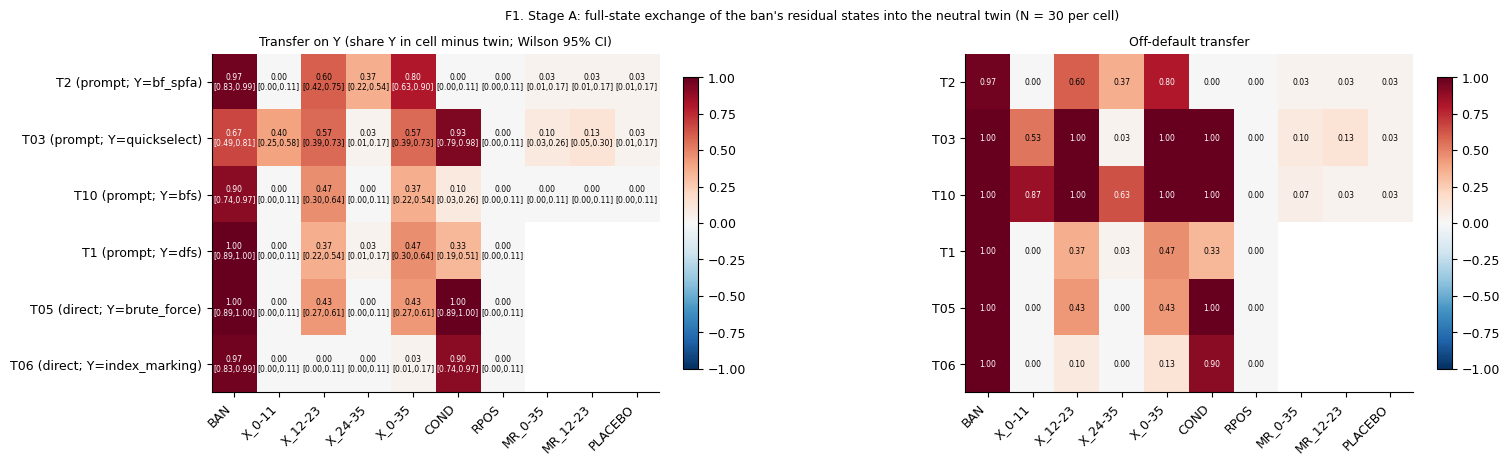

In [22]:
# src/figures6.py (excerpt): style constants and f1(), drawn from this notebook's stage_a() output instead of
# results/stage_a.json and shown inline instead of saved as PDF/PNG
OI = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#999999"]
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})
CELLS = ["BAN", "X_0-11", "X_12-23", "X_24-35", "X_0-35", "COND", "RPOS", "MR_0-35", "MR_12-23", "PLACEBO"]


def f1() -> None:
    a = stage_a_out["tasks"]  # notebook: original read_json(RESULTS_DIR / "stage_a.json")["tasks"]
    tasks = [t for t in ("T2", "T03", "T10", "T1", "T05", "T06") if t in a]
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw={"wspace": 0.55})
    for ax, key, title in ((axes[0], "transfer", "Transfer on Y (share Y in cell minus twin; Wilson 95% CI)"),
                           (axes[1], "off_default_transfer", "Off-default transfer")):
        M = np.full((len(tasks), len(CELLS)), np.nan)
        for i, t in enumerate(tasks):
            for j, c in enumerate(CELLS):
                v = a[t]["cells"].get(c, {}).get(key)
                if v is not None:
                    M[i, j] = v
        im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
        for i, t in enumerate(tasks):
            for j, c in enumerate(CELLS):
                cc = a[t]["cells"].get(c)
                if cc is None:
                    continue
                txt = f"{M[i, j]:.2f}"
                if key == "transfer":
                    lo, hi = cc["Y_ci95_wilson"]
                    txt += f"\n[{lo - a[t]['TWIN']['Y_share']:.2f},{hi - a[t]['TWIN']['Y_share']:.2f}]"
                ax.text(j, i, txt, ha="center", va="center", fontsize=5.5,
                        color="white" if abs(M[i, j]) > 0.6 else "black")
        ax.set_xticks(range(len(CELLS)), CELLS, rotation=45, ha="right")
        ax.set_yticks(range(len(tasks)), [f"{t} ({a[t]['route_class_iter2_3']}; Y={a[t]['Y']})" if key == "transfer"
                                          else t for t in tasks])
        ax.set_title(title, fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.03)
    fig.suptitle("F1. Stage A: full-state exchange of the ban's residual states into the neutral twin "
                 f"(N = {len(N30)} per cell)", fontsize=9)  # notebook: N from the config (original: N = 30)
    plt.show()  # notebook: original save(fig, "F1_stageA_transfer")


f1()

### 5.2 Summary figure (notebook addition)

- **(a)** The recorded Qwen3-8B Stage A in one picture: per task, the transfer produced by the spec-state exchange of all blocks (`X_0-35`) against the condition-span KV splice (`COND`). Prompt-route tasks sit high on the y-axis, direct-route tasks far to the right.
- **(b)-(d)** The live small model, in actual activation coordinates:
  - **(b)** Per block, how far the ban's residual states are from the twin's (relative L2 distance) at the condition span, the task-spec positions and the read position. The shaded regions are the exchange bands. The spec tokens are identical in both prompts, so any difference there was *written* into them by attention to the condition span.
  - **(c)** The spec-mean output of one middle block for twin, ban and placebo across the five templates, projected on their first two principal components.
  - **(d)** For every arm, on the CRN slots where the twin's and the ban's programs differ, the share of slots whose program is token for token the twin's or the ban's. The last column of the closing table repeats that share for the ban.
- A table of the headline numbers closes the notebook.

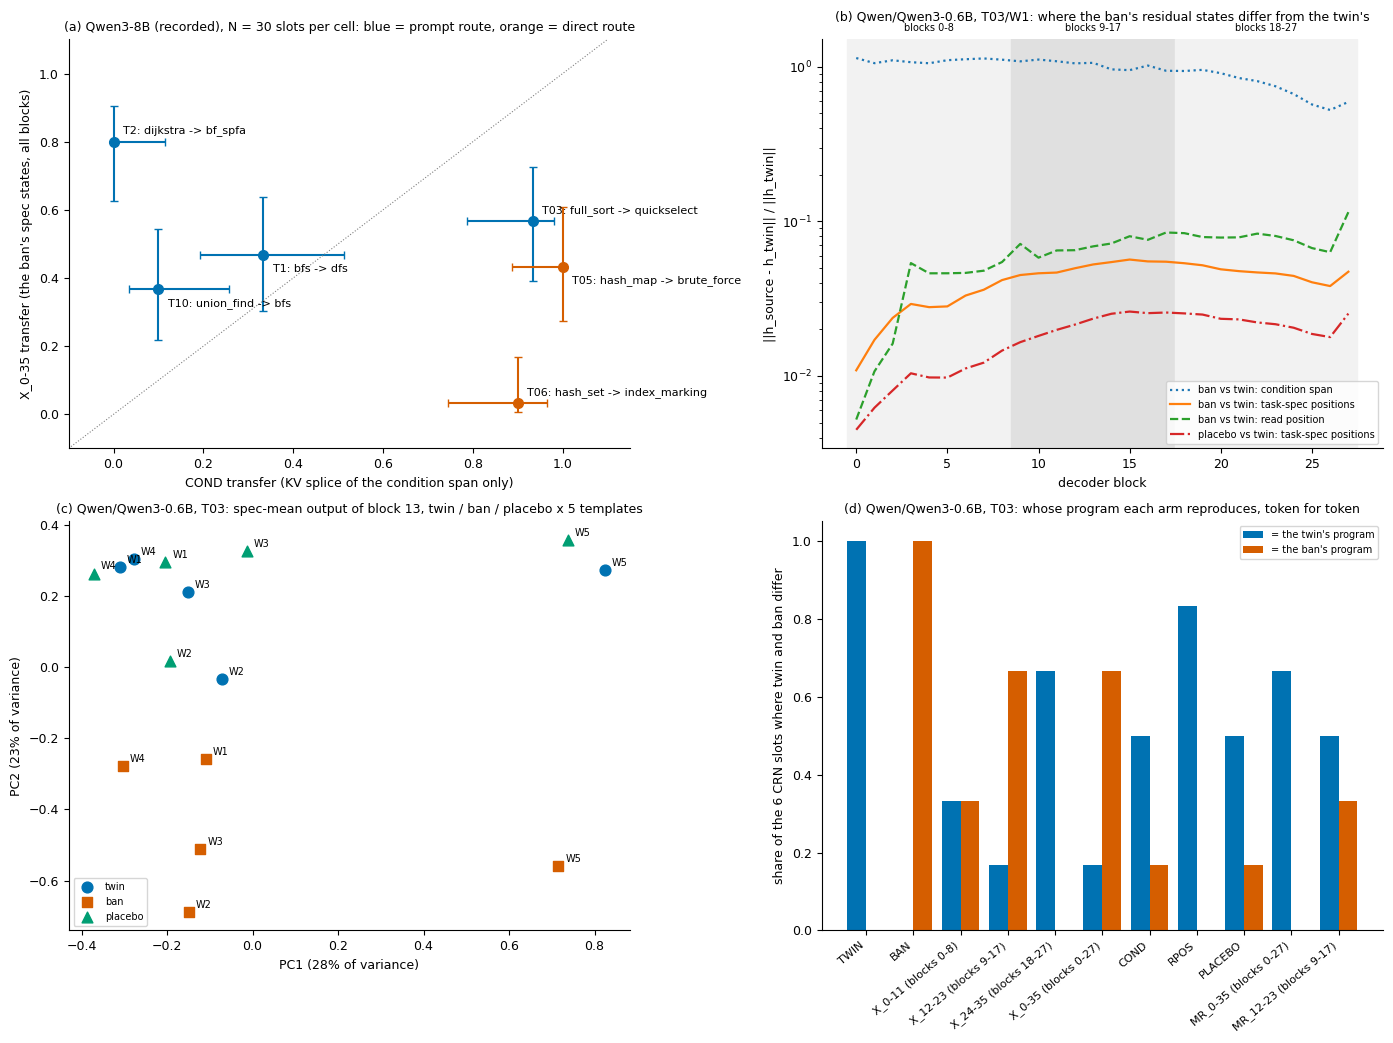

task  route    cell  8B transfer on Y 8B McNemar b:c    8B Holm p Qwen3-0.6B copies the ban's program
 T03 prompt X_12-23             0.567           17:0 7.629395e-05                                0.67
 T03 prompt  X_0-35             0.567           17:0 7.629395e-05                                0.67
 T03 prompt    COND             0.933           28:0 3.725290e-08                                0.17
 T03 prompt    RPOS             0.000            0:0 1.000000e+00                                 0.0
 T03 prompt MR_0-35             0.100            3:0 7.500000e-01                                 0.0
 T03 prompt PLACEBO             0.033            1:0 1.000000e+00                                0.17
 T10 prompt X_12-23             0.467           14:0 4.882812e-04                                   -
 T10 prompt  X_0-35             0.367           11:0 1.953125e-03                                   -
 T10 prompt    COND             0.100            3:0 5.000000e-01                 

In [23]:
# notebook addition: summary figure -- (a) the recorded Qwen3-8B route dissociation; (b)-(d) the live small model's
# residual states and programs, in actual activation coordinates
fig, axes = plt.subplots(2, 2, figsize=(14, 10.5))

# (a) Qwen3-8B: spec-state exchange of all blocks (X_0-35) against the condition-span KV splice (COND), Wilson 95% CIs
ax = axes[0, 0]
T = stage_a_out["tasks"]
for t in TASKS6:
    if t not in T:
        continue
    y_tw = T[t]["TWIN"]["Y_share"]
    pts_ = []
    for arm in ("COND", "X_0-35"):
        c = T[t]["cells"][arm]
        lo, hi = c["Y_ci95_wilson"]
        pts_.append((c["transfer"], [[c["Y_share"] - lo], [hi - c["Y_share"]]]))
    (x, xe), (y, ye) = pts_
    col = OI[5] if ROUTE_CLASS[t] == "prompt" else OI[6]
    ax.errorbar(x, y, xerr=xe, yerr=ye, fmt="o", color=col, capsize=3, ms=7)
    ax.annotate(f"{t}: {DEFAULT6[t]} -> {Y6[t]}", (x, y), textcoords="offset points",
                xytext=(7, 6 if TASKS6.index(t) % 2 == 0 else -12), fontsize=8)
ax.plot([-0.1, 1.1], [-0.1, 1.1], ls=":", color="grey", lw=0.8)
ax.set_xlim(-0.1, 1.15)
ax.set_ylim(-0.1, 1.1)
ax.set_xlabel("COND transfer (KV splice of the condition span only)")
ax.set_ylabel("X_0-35 transfer (the ban's spec states, all blocks)")
ax.set_title(f"(a) Qwen3-8B (recorded), N = {len(N30)} slots per cell: blue = prompt route, orange = direct route",
             fontsize=9)

# (b) small model: per block, how far the ban's (and the placebo's) states are from the twin's
t0_, w0_ = LIVE_TASKS[0], LIVE_TEMPLATES[0]
ctx = TaskW(model, P6, t0_, w0_, ("twin", "ban", "placebo") if (t0_, w0_, "placebo") in P6 else ("twin", "ban"))
tw = ctx.pr["twin"]


def rel_dist(src: Prompt, sl: slice) -> list[float]:
    """mean over positions of ||h_src - h_twin|| / ||h_twin|| at every block (block outputs captured by Prompt)"""
    return [max(float(((src.H[l][sl].float() - tw.H[l][sl].float()).norm(dim=-1) /
                       tw.H[l][sl].float().norm(dim=-1)).mean()), 1e-6) for l in ALL_BLOCKS]


ax = axes[0, 1]
curves = [("ban vs twin: condition span", ctx.pr["ban"], tw.iC, ":"),
          ("ban vs twin: task-spec positions", ctx.pr["ban"], tw.iS, "-"),
          ("ban vs twin: read position", ctx.pr["ban"], slice(tw.iR, tw.iR + 1), "--")]
if "placebo" in ctx.pr:
    curves.append(("placebo vs twin: task-spec positions", ctx.pr["placebo"], tw.iS, "-."))
for name, src, sl, ls in curves:
    ax.plot(ALL_BLOCKS, rel_dist(src, sl), ls, label=name, lw=1.6)
for i, (b, blocks) in enumerate(BANDS.items()):
    if b != "0-35":
        ax.axvspan(blocks[0] - 0.5, blocks[-1] + 0.5, color=("#f2f2f2", "#e0e0e0", "#f2f2f2")[i], zorder=0)
        ax.text((blocks[0] + blocks[-1]) / 2, 1.02, BAND_LABEL[f"X_{b}"].split(" (")[1].rstrip(")"),
                transform=ax.get_xaxis_transform(), ha="center", fontsize=7)
ax.set_yscale("log")
ax.set_xlabel("decoder block")
ax.set_ylabel("||h_source - h_twin|| / ||h_twin||")
ax.set_title(f"(b) {MODEL_ID}, {t0_}/{w0_}: where the ban's residual states differ from the twin's", fontsize=9,
             pad=14)
ax.legend(fontsize=7)

# (c) small model: spec-mean outputs of a middle block for twin / ban / placebo on every template, first two PCs
ax = axes[1, 0]
lmid = BANDS["12-23"][len(BANDS["12-23"]) // 2]
pts, labs = [], []
for w in ("W1", "W2", "W3", "W4", "W5"):
    for kind in ("twin", "ban", "placebo"):
        if (t0_, w, kind) in P6:
            pr = Prompt(model, P6[(t0_, w, kind)])  # clean prefill, captures every block at [SPEC..., R, COND...]
            pts.append(pr.H[lmid][pr.iS].float().mean(0).cpu().numpy())
            labs.append((w, kind))
            del pr
X = np.stack(pts)
Xc = X - X.mean(0)
_, Sv, Vt = np.linalg.svd(Xc, full_matrices=False)
Z = Xc @ Vt[:2].T
KIND_STYLE = {"twin": ("o", OI[5]), "ban": ("s", OI[6]), "placebo": ("^", OI[3])}
for (w, kind), z in zip(labs, Z):
    mk, col = KIND_STYLE[kind]
    ax.scatter(z[0], z[1], marker=mk, color=col, s=60, label=kind if w == "W1" else None)
    ax.annotate(w, (z[0], z[1]), textcoords="offset points", xytext=(5, 3), fontsize=7)
ev = Sv ** 2 / np.sum(Sv ** 2)
ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({ev[1]:.0%} of variance)")
ax.set_title(f"(c) {MODEL_ID}, {t0_}: spec-mean output of block {lmid}, twin / ban / placebo x 5 templates",
             fontsize=9)
ax.legend(fontsize=7)

# (d) small model: which source each arm's program copies, token for token, slot by slot
ax = axes[1, 1]
order = [a for a in ("TWIN", "BAN", "X_0-11", "X_12-23", "X_24-35", "X_0-35", "COND", "RPOS", "PLACEBO", "MR_0-35",
                     "MR_12-23") if a in set(live_df[live_df["task"] == t0_]["arm"])]
inf = live_df[(live_df["task"] == t0_) & live_df["informative"]]  # slots where the twin's and the ban's programs differ
g = inf.groupby("arm")[["same_as_twin", "same_as_ban"]].mean().reindex(order)
xs = np.arange(len(order))
ax.bar(xs - 0.2, g["same_as_twin"], 0.4, label="= the twin's program", color=OI[5])
ax.bar(xs + 0.2, g["same_as_ban"], 0.4, label="= the ban's program", color=OI[6])
ax.set_xticks(xs, [BAND_LABEL.get(a, a) for a in order], rotation=40, ha="right", fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel(f"share of the {inf['slot'].nunique()} CRN slots where twin and ban differ")
ax.set_title(f"(d) {MODEL_ID}, {t0_}: whose program each arm reproduces, token for token", fontsize=9)
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()
ctx.free()

# the headline numbers in one table: recorded Qwen3-8B (this notebook's re-derivation) next to the live small model
summ = []
for t in TASKS6:
    for arm in ("X_12-23", "X_0-35", "COND", "RPOS", "MR_0-35", "PLACEBO"):
        c = T.get(t, {}).get("cells", {}).get(arm)
        if c is None:
            continue
        lv = g.loc[arm] if (t == t0_ and arm in g.index) else None
        summ.append({"task": t, "route": ROUTE_CLASS[t], "cell": arm, "8B transfer on Y": round(c["transfer"], 3),
                     "8B McNemar b:c": f"{c['mcnemar_vs_twin']['b_Y_only_cell']}:{c['mcnemar_vs_twin']['c_Y_only_twin']}",
                     "8B Holm p": c["mcnemar_vs_twin"].get("p_holm"),
                     f"{MODEL_ID.split('/')[-1]} copies the ban's program": "-" if lv is None else round(float(lv["same_as_ban"]), 2)})
print(pd.DataFrame(summ).to_string(index=False))

## Takeaways

- **Re-derived from the recorded Qwen3-8B programs.** On the prompt-route tasks the ban is carried by the task-specification states. On T2, exchanging the ban's spec states of all blocks gives a transfer of 0.80 (McNemar 24:0, Holm p 7.2e-7), and of blocks 12-23 alone 0.60. On the direct-route tasks, the condition-span KV splice alone reproduces the ban (T05 1.00, T06 0.90), while the read position transfers nothing on any task. The matched-norm random exchanges stay at or below 0.13 and the placebo at or below 0.033. All 369 checked numbers equal the artifact's own `results/stage_a.json`, and the swap placebos fail as they should.
- **The committed verdicts.** P1 is **NOT SUPPORTED**, because T05's spec states also transfer 0.43. The route check, the placebo and the MR predictions hold.
- **The same code live on Qwen3-0.6B.** Exchanging the ban's spec states of the middle third, or of all blocks, reproduces the ban's own program in 4 of 6 informative slots; every other arm does so in at most 2. The late third, the read position and `MR_0-35` never do, and the placebo and `COND` do so once. In this small model, then, the middle third of the spec states is enough to carry the ban's effect on the program, and the size of the perturbation alone does not reproduce it. With 8 slots this is an illustration, not a test.
- **Full scale.** Set the configuration cell to the original values (Qwen3-8B on a 16 GB GPU, six tasks, 30 slots per cell) to rerun Stage A as the artifact did; Part 2 then shows the numbers such a run produced.